Objetivo: Construir y comparar modelos de Machine Learning (Random Forest y Árboles de Decisión) capaces de clasificar el tipo de tumor de un paciente (BRCA, KIRC, COAD, LUAD o PRAD) a partir de los niveles de expresión de 20.531 genes obtenidos por RNA-Seq (plataforma Illumina HiSeq), y analizar, mediante reducción de dimensionalidad (PCA), qué genes aportan más información para discriminar entre los distintos tipos de cáncer.

**Dataset:** Gene Expression Cancer RNA-Seq (TCGA-PANCAN-HiSeq)

**Procedencia:** `https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq`

**Descripción:** Extracción aleatoria de perfiles de expresión génica de pacientes con cinco tipos de tumores (BRCA, KIRC, COAD, LUAD, PRAD), obtenidos por RNA-Seq (Illumina HiSeq). Forma parte del proyecto TCGA-PANCAN y fue publicado en UCI Machine Learning Repository (ID 401).

**Estructura:** 801 muestras × 20.532 columnas:
- 20.531 features numéricas (`gene_0` … `gene_20530`): niveles de expresión génica.
- 1 variable objetivo categórica (`Class`): tipo de tumor (5 clases).

-dimensionalidad (p ≫ n): 20.531 features para 801 muestras.


## Parte 01

In [ ]:
# ============================================
# PARTE 1: Montar Drive, descomprimir y cargar datos
# ============================================

# 1. Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Definir la ruta del archivo .tar.gz
ruta_tar = '/content/drive/MyDrive/Unsta/4to año/Bioinformatica/Proyecto 02/gene+expression+cancer+rna+seq/TCGA-PANCAN-HiSeq-801x20531.tar.gz'

# 3. Verificar que el archivo existe
import os
print("¿Existe el archivo?", os.path.exists(ruta_tar))

# 4. Crear carpeta de destino y descomprimir
carpeta_destino = '/content/datos_pancan'
os.makedirs(carpeta_destino, exist_ok=True)

!tar -xzvf "{ruta_tar}" -C "{carpeta_destino}"

# 5. Ver qué archivos se extrajeron
print("\nArchivos extraídos:")
for root, dirs, files in os.walk(carpeta_destino):
    for f in files:
        print(os.path.join(root, f))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
¿Existe el archivo? True
TCGA-PANCAN-HiSeq-801x20531/
TCGA-PANCAN-HiSeq-801x20531/data.csv
TCGA-PANCAN-HiSeq-801x20531/labels.csv

Archivos extraídos:
/content/datos_pancan/TCGA-PANCAN-HiSeq-801x20531/labels.csv
/content/datos_pancan/TCGA-PANCAN-HiSeq-801x20531/data.csv


In [ ]:
# 6. Cargar los datos en DataFrames
import pandas as pd

# Ajustá estas rutas según lo que haya mostrado el paso 5
ruta_data   = '/content/datos_pancan/TCGA-PANCAN-HiSeq-801x20531/data.csv'
ruta_labels = '/content/datos_pancan/TCGA-PANCAN-HiSeq-801x20531/labels.csv'

data   = pd.read_csv(ruta_data, index_col=0)
labels = pd.read_csv(ruta_labels, index_col=0)

# 7. Unir features + etiqueta en un solo DataFrame
df = data.copy()
df['Class'] = labels['Class']

print("Dimensiones del dataset:", df.shape)
print("\nPrimeras filas (solo las primeras 5 columnas + Class):")
print(df.iloc[:, :5].join(df['Class']).head())

print("\nDistribución de clases:")
print(df['Class'].value_counts())

Dimensiones del dataset: (801, 20532)

Primeras filas (solo las primeras 5 columnas + Class):
          gene_0    gene_1    gene_2    gene_3     gene_4 Class
sample_0     0.0  2.017209  3.265527  5.478487  10.431999  PRAD
sample_1     0.0  0.592732  1.588421  7.586157   9.623011  LUAD
sample_2     0.0  3.511759  4.327199  6.881787   9.870730  PRAD
sample_3     0.0  3.663618  4.507649  6.659068  10.196184  PRAD
sample_4     0.0  2.655741  2.821547  6.539454   9.738265  BRCA

Distribución de clases:
Class
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64


## Parte 02

In [ ]:
# ============================================
# PARTE 2: Exploración descriptiva del dataset
# ============================================

import pandas as pd
import numpy as np

# ---------------------------------------------------------
# PREGUNTA 1: ¿Cuántas columnas hay? Describir cada una.
# ---------------------------------------------------------
print("="*60)
print("1. COLUMNAS DEL DATASET")
print("="*60)

n_columnas = df.shape[1]
n_features  = n_columnas - 1  # todas menos 'Class'

print(f"Cantidad total de columnas: {n_columnas}")
print(f"  - Features (genes): {n_features}")
print(f"  - Variable objetivo ('Class'): 1")

print("\nTipos de columnas:")
print(f"  - Columnas de expresión génica: {df.columns[:-1][:5].tolist()} ... "
      f"{df.columns[:-1][-3:].tolist()}  (nombres tipo 'gene_XX')")
print(f"  - Columna objetivo: '{df.columns[-1]}'")

# Mostrar las primeras y últimas columnas
print("\nPrimeras 5 columnas:", df.columns[:5].tolist())
print("Última columna:", df.columns[-1])

1. COLUMNAS DEL DATASET
Cantidad total de columnas: 20532
  - Features (genes): 20531
  - Variable objetivo ('Class'): 1

Tipos de columnas:
  - Columnas de expresión génica: ['gene_0', 'gene_1', 'gene_2', 'gene_3', 'gene_4'] ... ['gene_20528', 'gene_20529', 'gene_20530']  (nombres tipo 'gene_XX')
  - Columna objetivo: 'Class'

Primeras 5 columnas: ['gene_0', 'gene_1', 'gene_2', 'gene_3', 'gene_4']
Última columna: Class




### ¿Cuántas columnas hay? Descripción de cada una

El dataset contiene **20.532 columnas** en total, que se agrupan en dos tipos:

| Grupo | Cantidad | Nombres de columnas | Tipo de dato | Descripción |
|---|---|---|---|---|
| **Features (genes)** | **20.531** | `gene_0`, `gene_1`, …, `gene_20530` | Numérico continuo (`float64`) | Niveles de expresión génica de cada muestra, medidos por RNA-Seq (plataforma Illumina HiSeq). Cada columna representa un gen distinto; el nombre es ficticio (`gene_XX`) porque el dataset original anonimiza los identificadores de las sondas. Los valores están transformados (escala tipo log), por lo que el mínimo es 0 y el máximo es acotado. |
| **Variable objetivo (target)** | **1** | `Class` | Categórico (`object`) | Tipo de tumor del paciente. Toma 5 valores: **BRCA** (mama), **KIRC** (riñón), **COAD** (colon), **LUAD** (pulmón) y **PRAD** (próstata). |

**Resumen:**
- **20.531 features numéricas** (genes) + **1 variable objetivo categórica** (`Class`).
- Las features están ordenadas de forma consistente con el dataset original (PANCAN), pero al tener nombres ficticios no se puede identificar el gen real sin el mapeo de la submission original (actualmente con acceso restringido en Synapse).
- La unidad de medida de las features es el nivel de expresión relativo (adimensional tras la transformación).

In [ ]:
# ---------------------------------------------------------
# PREGUNTA 2: ¿Cuántos datos tiene el conjunto de datos?
# ---------------------------------------------------------
print("\n" + "="*60)
print("2. CANTIDAD DE DATOS (FILAS / MUESTRAS)")
print("="*60)

print(f"Filas (muestras/pacientes): {df.shape[0]}")
print(f"Columnas (features + target): {df.shape[1]}")
print(f"Total de celdas: {df.shape[0] * df.shape[1]:,}")



2. CANTIDAD DE DATOS (FILAS / MUESTRAS)
Filas (muestras/pacientes): 801
Columnas (features + target): 20532
Total de celdas: 16,446,132


### ¿Cuántos datos tiene el conjunto de datos?

El dataset tiene **801 filas (muestras/pacientes)** y **20.532 columnas**, lo que equivale a un total de **16.446.132 celdas** (801 × 20.532).

- **801 instancias**: cada fila corresponde a una muestra de tejido tumoral de un paciente.
- **20.531 features + 1 variable objetivo**: cada fila contiene los niveles de expresión de 20.531 genes y la etiqueta `Class` con el tipo de tumor.

Se trata de un dataset **pequeño en cantidad de filas pero de altísima dimensionalidad** (20.531 features para solo 801 muestras), lo que constituye un caso típico de **p ≫ n** (más variables que observaciones). Esta característica justifica el uso de técnicas de reducción de dimensionalidad (PCA) y de modelos robustos a muchas features (Random Forest, Árboles de Decisión) en las etapas posteriores del análisis.

In [ ]:
# ---------------------------------------------------------
# PREGUNTA 3: Variable objetivo, clases y cantidad
# ---------------------------------------------------------
print("\n" + "="*60)
print("3. VARIABLE OBJETIVO Y CLASES")
print("="*60)

variable_objetivo = df.columns[-1]
print(f"Variable objetivo: '{variable_objetivo}'")

clases = df[variable_objetivo].unique()
print(f"Cantidad de clases: {len(clases)}")
print(f"Clases: {sorted(clases.tolist())}")

print("\nDistribución de muestras por clase:")
print(df[variable_objetivo].value_counts())
print("\nPorcentaje por clase:")
print((df[variable_objetivo].value_counts(normalize=True) * 100).round(2))


3. VARIABLE OBJETIVO Y CLASES
Variable objetivo: 'Class'
Cantidad de clases: 5
Clases: ['BRCA', 'COAD', 'KIRC', 'LUAD', 'PRAD']

Distribución de muestras por clase:
Class
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64

Porcentaje por clase:
Class
BRCA    37.45
KIRC    18.23
LUAD    17.60
PRAD    16.98
COAD     9.74
Name: proportion, dtype: float64


### ¿Cuál es la variable objetivo, y cuáles y cuántas son las clases que toma?

La **variable objetivo** es **`Class`**, de tipo categórico, que indica el tipo de tumor del paciente.

Toma **5 clases**:

| Clase | Significado | Cantidad de muestras |
|---|---|---|
| **BRCA** | Breast invasive carcinoma (cáncer de mama invasivo) | 300 |
| **KIRC** | Kidney renal clear cell carcinoma (carcinoma de células claras de riñón) | 146 |
| **LUAD** | Lung adenocarcinoma (adenocarcinoma de pulmón) | 141 |
| **PRAD** | Prostate adenocarcinoma (adenocarcinoma de próstata) | 136 |
| **COAD** | Colon adenocarcinoma (adenocarcinoma de colon) | 78 |

**Total: 801 muestras**, coincidente con la cantidad de filas del dataset.

In [ ]:
# ---------------------------------------------------------
# PREGUNTA 4: ¿Cuántos features numéricos y categóricos?
# ---------------------------------------------------------
print("\n" + "="*60)
print("4. FEATURES NUMÉRICOS vs CATEGÓRICOS")
print("="*60)

# Tipos de datos de todas las columnas
print("Tipos de datos (dtypes):")
print(df.dtypes.value_counts())

# Separar features (todo menos 'Class')
X_features = df.drop(columns=[variable_objetivo])

num_features = X_features.select_dtypes(include=[np.number]).shape[1]
cat_features = X_features.select_dtypes(include=['object', 'category']).shape[1]

print(f"\nFeatures numéricos:   {num_features}")
print(f"Features categóricos: {cat_features}")
print(f"(La variable objetivo '{variable_objetivo}' es categórica: "
      f"{df[variable_objetivo].dtype})")



4. FEATURES NUMÉRICOS vs CATEGÓRICOS
Tipos de datos (dtypes):
float64    20531
object         1
Name: count, dtype: int64

Features numéricos:   20531
Features categóricos: 0
(La variable objetivo 'Class' es categórica: object)


### ¿Cuántos features numéricos y categóricos tiene?

- **Features numéricos: 20.531** (todas las columnas `gene_0` … `gene_20530`, de tipo `float64`).
- **Features categóricos: 0** (no hay features categóricas en `X`).

Todas las features del dataset son **numéricas continuas**. La única columna categórica es la **variable objetivo `Class`** (tipo `object`), que no es una feature sino la etiqueta a predecir.

| Tipo | Cantidad | Columnas | dtype |
|---|---|---|---|
| Numéricos | 20.531 | `gene_0` … `gene_20530` | `float64` |
| Categóricos (features) | 0 | — | — |
| Categórico (target) | 1 | `Class` | `object` |


In [ ]:
# ---------------------------------------------------------
# PREGUNTA 5: Mínimos y máximos de las features numéricas
# ---------------------------------------------------------
print("\n" + "="*60)
print("5. MÍNIMOS Y MÁXIMOS DE LAS FEATURES NUMÉRICAS")
print("="*60)

# Mínimos y máximos de todas las features
tabla_rangos = pd.DataFrame({
    'Minimo': X_features.min(),
    'Maximo': X_features.max()
})

display(tabla_rangos)

# Guardar tabla
tabla_rangos.to_csv('rangos_features.csv')

# describe() da estadísticas de todas las columnas numéricas
desc = X_features.describe()

print("Estadísticas globales (resumen de describe()):")
print(desc.T[['min', 'max']].describe().loc[['min', 'max']])

# Valores concretos: mínimo global y máximo global entre TODOS los genes
min_global = desc.loc['min'].min()
max_global = desc.loc['max'].max()

print(f"\nMínimo global entre todas las features numéricas: {min_global}")
print(f"Máximo global entre todas las features numéricas: {max_global}")

# Ejemplo con las primeras 5 features
print("\nMín/Máx de las primeras 5 features (ejemplo):")
print(desc.loc[['min', 'max'], desc.columns[:5]])

# Features con el mínimo más bajo y el máximo más alto
print(f"\nFeature con mínimo más bajo:  '{desc.loc['min'].idxmin()}' -> {desc.loc['min'].min()}")
print(f"Feature con máximo más alto:  '{desc.loc['max'].idxmax()}' -> {desc.loc['max'].max()}")


5. MÍNIMOS Y MÁXIMOS DE LAS FEATURES NUMÉRICAS


,Minimo,Maximo
gene_0,0.000000,1.482332
gene_1,0.000000,6.237034
gene_2,0.000000,6.063484
gene_3,5.009284,10.129528
gene_4,8.435999,11.355621
...,...,...
gene_20526,9.045255,13.715361
gene_20527,7.530141,11.675653
gene_20528,7.864533,12.813320
gene_20529,0.593975,11.205836


Estadísticas globales (resumen de describe()):
           min        max
min   0.000000   0.000000
max  14.841294  20.778829

Mínimo global entre todas las features numéricas: 0.0
Máximo global entre todas las features numéricas: 20.7788287118

Mín/Máx de las primeras 5 features (ejemplo):
       gene_0    gene_1    gene_2     gene_3     gene_4
min  0.000000  0.000000  0.000000   5.009284   8.435999
max  1.482332  6.237034  6.063484  10.129528  11.355621

Feature con mínimo más bajo:  'gene_0' -> 0.0
Feature con máximo más alto:  'gene_4160' -> 20.7788287118


###¿De las features numéricas, cuáles son sus mínimos y máximos?
Se calcularon los valores mínimos y máximos de cada una de las 20.531 features numéricas del conjunto de datos. Para ello, se utilizó el método `describe()`, extrayendo las estadísticas correspondientes a `min` y `max`.

Se observó que los valores presentan diferentes rangos según el gen analizado. El mínimo global entre todas las features es **0**, mientras que el máximo global es aproximadamente **20,7788**, correspondiente a la feature `gene_4160`.

Estos resultados permiten conocer el rango de valores de expresión de cada gen e identificar posibles diferencias de escala entre las variables.

In [ ]:
# ---------------------------------------------------------
# PREGUNTA 6: Valores únicos de las features categóricas
# ---------------------------------------------------------
print("\n" + "="*60)
print("6. VALORES ÚNICOS DE LAS FEATURES CATEGÓRICAS")
print("="*60)

# Features categóricas (excluyendo la target)
cat_cols = X_features.select_dtypes(include=['object', 'category']).columns.tolist()

if len(cat_cols) == 0:
    print("No hay features categóricas en X (todas son numéricas).")
else:
    for col in cat_cols:
        print(f"  '{col}': {X_features[col].nunique()} valores únicos -> "
              f"{X_features[col].unique().tolist()}")

# La variable objetivo SÍ es categórica: mostramos sus valores únicos
print(f"\nVariable objetivo '{variable_objetivo}': "
      f"{df[variable_objetivo].nunique()} valores únicos -> "
      f"{df[variable_objetivo].unique().tolist()}")



6. VALORES ÚNICOS DE LAS FEATURES CATEGÓRICAS
No hay features categóricas en X (todas son numéricas).

Variable objetivo 'Class': 5 valores únicos -> ['PRAD', 'LUAD', 'BRCA', 'KIRC', 'COAD']


### ¿De las features categóricas, cuántos valores únicos tienen?

**No hay features categóricas en `X`**: las 20.531 features del dataset son todas numéricas (`float64`). Por lo tanto, no hay valores únicos que reportar para features categóricas.

La **única columna categórica** del dataset es la **variable objetivo `Class`**, que tiene **5 valores únicos**:

`['PRAD', 'LUAD', 'BRCA', 'KIRC', 'COAD']`

| Columna | Tipo | Rol | Valores únicos |
|---|---|---|---|
| `gene_0` … `gene_20530` | `float64` | Features | Numéricas continuas (no aplica) |
| `Class` | `object` | Variable objetivo | **5**: PRAD, LUAD, BRCA, KIRC, COAD |

## Parte 03

In [ ]:
# ============================================
# PARTE 3: PREPARACIÓN DE LOS DATOS
# ============================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

# =========================================================
# 1. ¿HAY VALORES FALTANTES? ¿CUÁNTOS?
# =========================================================
print("="*60)
print("1. VALORES FALTANTES")
print("="*60)

total_faltantes = df.isnull().sum().sum()
print(f"Total de valores faltantes en todo el DataFrame: {total_faltantes}")

cols_con_faltantes = df.isnull().sum()
cols_con_faltantes = cols_con_faltantes[cols_con_faltantes > 0]
print(f"Columnas con al menos un faltante: {len(cols_con_faltantes)}")

filas_con_faltantes = df.isnull().any(axis=1).sum()
print(f"Filas con al menos un faltante: {filas_con_faltantes}")

1. VALORES FALTANTES
Total de valores faltantes en todo el DataFrame: 0
Columnas con al menos un faltante: 0
Filas con al menos un faltante: 0


In [ ]:
# =========================================================
# 2. SI ELIMINÁRAMOS FILAS CON FALTANTES, ¿CUÁNTAS?
# =========================================================
print("\n" + "="*60)
print("2. FILAS QUE SE ELIMINARÍAN CON dropna()")
print("="*60)

filas_a_eliminar = df.isnull().any(axis=1).sum()
print(f"Filas que se eliminarían: {filas_a_eliminar}")
print(f"Filas restantes: {df.shape[0] - filas_a_eliminar} de {df.shape[0]}")

# (Opcional) Aplicar dropna() igual, por prolijidad, aunque no elimine nada
datos_limpios = df.dropna().copy()
print(f"\nDespués de aplicar dropna(): {datos_limpios.shape[0]} filas, "
      f"{datos_limpios.shape[1]} columnas")


2. FILAS QUE SE ELIMINARÍAN CON dropna()
Filas que se eliminarían: 0
Filas restantes: 801 de 801

Después de aplicar dropna(): 801 filas, 20532 columnas


### ¿Hay valores faltantes? ¿Cuántos?

**No hay valores faltantes en el dataset.** El conteo total de valores nulos es **0** sobre las 801 filas × 20.532 columnas.

| Chequeo | Resultado |
|---|---|
| Valores faltantes totales | **0** |
| Columnas con al menos un faltante | **0** |
| Filas con al menos un faltante | **0** |

### Si deciden eliminar las filas con valores faltantes, ¿cuántas eliminarían?

Se eliminarían **0 filas**. Al aplicar `dropna()`, el dataset quedaría idéntico: se conservan las **801 de 801 filas**.

In [ ]:
# =========================================================
# 3. PASAR VARIABLES CATEGÓRICAS A NÚMEROS (LabelEncoder)
# =========================================================
print("\n" + "="*60)
print("3. CODIFICACIÓN CON LabelEncoder")
print("="*60)

# 3a. Features categóricas (no hay en X, pero lo dejamos preparado)
X_features = datos_limpios.drop(columns=['Class'])
cat_cols = X_features.select_dtypes(include=['object', 'category']).columns.tolist()

if len(cat_cols) == 0:
    print("Features categóricas en X: 0 (todas las features ya son numéricas).")
    print("-> No es necesario aplicar LabelEncoder sobre X.")
else:
    print(f"Features categóricas encontradas: {cat_cols}")
    for col in cat_cols:
        le = LabelEncoder()
        datos_limpios[col] = le.fit_transform(datos_limpios[col])
        print(f"  '{col}' codificada -> {dict(zip(le.classes_, le.transform(le.classes_)))}")

# 3b. Variable objetivo 'Class' (sí es categórica: hay que codificarla)
print("\nVariable objetivo 'Class' antes de codificar:")
print(f"  Valores únicos: {datos_limpios['Class'].unique().tolist()}")

le_target = LabelEncoder()
datos_limpios['Class'] = le_target.fit_transform(datos_limpios['Class'])

print("\nVariable objetivo 'Class' DESPUÉS de codificar:")
mapeo = dict(zip(le_target.classes_, le_target.transform(le_target.classes_)))
print(f"  Mapeo clase -> número: {mapeo}")
print(f"  Valores únicos codificados: {sorted(datos_limpios['Class'].unique().tolist())}")
print(f"  dtype de 'Class': {datos_limpios['Class'].dtype}")


3. CODIFICACIÓN CON LabelEncoder
Features categóricas en X: 0 (todas las features ya son numéricas).
-> No es necesario aplicar LabelEncoder sobre X.

Variable objetivo 'Class' antes de codificar:
  Valores únicos: ['PRAD', 'LUAD', 'BRCA', 'KIRC', 'COAD']

Variable objetivo 'Class' DESPUÉS de codificar:
  Mapeo clase -> número: {'BRCA': np.int64(0), 'COAD': np.int64(1), 'KIRC': np.int64(2), 'LUAD': np.int64(3), 'PRAD': np.int64(4)}
  Valores únicos codificados: [0, 1, 2, 3, 4]
  dtype de 'Class': int64


In [ ]:
# =========================================================
# 4. GUARDAR EL DATAFRAME LIMPIO EN ARCHIVO DE TEXTO
# =========================================================
print("\n" + "="*60)
print("4. GUARDAR DATAFRAME LIMPIO")
print("="*60)

datos_limpios.to_csv('datos_limpios.txt', index=False)
print("Archivo guardado: 'datos_limpios.txt'")
print(f"Dimensiones guardadas: {datos_limpios.shape[0]} filas × {datos_limpios.shape[1]} columnas")

# Verificación: leer el archivo guardado
verificacion = pd.read_csv('datos_limpios.txt')
print(f"\nVerificación (releído del archivo): {verificacion.shape[0]} filas × "
      f"{verificacion.shape[1]} columnas")
print("Primeras 3 filas (solo 'Class' y primeras 3 columnas):")
print(verificacion.iloc[:3, [0, 1, 2, -1]])


4. GUARDAR DATAFRAME LIMPIO
Archivo guardado: 'datos_limpios.txt'
Dimensiones guardadas: 801 filas × 20532 columnas

Verificación (releído del archivo): 801 filas × 20532 columnas
Primeras 3 filas (solo 'Class' y primeras 3 columnas):
   gene_0    gene_1    gene_2  Class
0     0.0  2.017209  3.265527      4
1     0.0  0.592732  1.588421      3
2     0.0  3.511759  4.327199      4


In [ ]:
# =========================================================
# 5. ¿LAS CLASES ESTÁN BALANCEADAS? ¿CUÁNTOS DATOS POR CLASE?
# =========================================================
print("\n" + "="*60)
print("5. BALANCE DE CLASES")
print("="*60)

conteo_clases = datos_limpios['Class'].value_counts().sort_index()
print("Cantidad de datos por clase (codificada):")
print(conteo_clases)

# Volvemos a los nombres originales para que sea legible
conteo_original = df['Class'].value_counts()
print("\nCantidad de datos por clase (nombre original):")
print(conteo_original)

print("\nPorcentaje por clase:")
print((df['Class'].value_counts(normalize=True) * 100).round(2))

# Evaluación del balance
max_clase = conteo_original.max()
min_clase = conteo_original.min()
ratio = max_clase / min_clase
print(f"\nClase mayoritaria: {conteo_original.idxmax()} ({max_clase} muestras)")
print(f"Clase minoritaria: {conteo_original.idxmin()} ({min_clase} muestras)")
print(f"Ratio mayoritaria/minoritaria: {ratio:.2f} : 1")

if ratio < 1.5:
    print("-> Las clases están BALANCEADAS.")
elif ratio < 3:
    print("-> Las clases están MODERADAMENTE desbalanceadas.")
else:
    print("-> Las clases están DESBALANCEADAS.")


5. BALANCE DE CLASES
Cantidad de datos por clase (codificada):
Class
0    300
1     78
2    146
3    141
4    136
Name: count, dtype: int64

Cantidad de datos por clase (nombre original):
Class
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64

Porcentaje por clase:
Class
BRCA    37.45
KIRC    18.23
LUAD    17.60
PRAD    16.98
COAD     9.74
Name: proportion, dtype: float64

Clase mayoritaria: BRCA (300 muestras)
Clase minoritaria: COAD (78 muestras)
Ratio mayoritaria/minoritaria: 3.85 : 1
-> Las clases están DESBALANCEADAS.


### ¿Las clases están balanceadas? ¿Cuántos datos tiene cada una de ellas?

**No, las clases no están balanceadas.** La distribución es la siguiente:

| Clase | Significado | Muestras | Porcentaje |
|---|---|---|---|
| **BRCA** | Breast invasive carcinoma (mama) | 300 | 37.45% |
| **KIRC** | Kidney renal clear cell carcinoma (riñón) | 146 | 18.23% |
| **LUAD** | Lung adenocarcinoma (pulmón) | 141 | 17.60% |
| **PRAD** | Prostate adenocarcinoma (próstata) | 136 | 16.98% |
| **COAD** | Colon adenocarcinoma (colon) | 78 | 9.74% |
| **Total** | | **801** | 100% |

**Análisis del desbalance:**
- Clase mayoritaria: **BRCA** (300 muestras, ~37.5%).
- Clase minoritaria: **COAD** (78 muestras, ~9.7%).
- Ratio mayoritaria/minoritaria ≈ **3.85 : 1**.

Las clases KIRC, LUAD y PRAD están relativamente equilibradas entre sí (136–146 muestras), pero todas están por debajo de BRCA.

#Parte 04


In [ ]:
# ============================================
# PARTE 4: VISUALIZACIÓN Y REDUCCIÓN DE DIMENSIONALIDAD
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.decomposition import PCA

# =========================================================
# 1. ¿CUÁNTAS DIMENSIONES HABRÍA PARA GRAFICAR CON TODOS LOS FEATURES?
# =========================================================
print("="*60)
print("1. DIMENSIONALIDAD")
print("="*60)

n_features = datos_limpios.shape[1] - 1  # todas menos 'Class'
print(f"Cantidad de features (genes): {n_features}")


1. DIMENSIONALIDAD
Cantidad de features (genes): 20531


### ¿Cuántas dimensiones habría en el caso que uno quisiera utilizar directamente a todos los features para graficar?

Se necesitarían **20.531 dimensiones**, una por cada gen del dataset. Cada muestra (paciente) sería un punto en un espacio de 20.531 ejes, lo cual es **imposible de visualizar**

Esto constituye un caso extremo de **maldición de la dimensionalidad** (*curse of dimensionality*):
- No es posible graficar en 20.531 dimensiones.
- Las distancias entre puntos pierden significado en espacios de tan alta dimensión.
- Con 801 muestras y 20.531 features (p ≫ n), los modelos son propensos al sobreajuste.

Por estas razones, en la etapa siguiente se aplica **PCA** para reducir las 20.531 dimensiones a **2 componentes principales (PC1 y PC2)**, conservando la mayor cantidad posible de varianza y permitiendo visualizar si las clases (tipos de tumor) se separan en el plano.

In [ ]:
# =========================================================
# 2. ¿LAS FEATURES ESTÁN MEDIDAS CON LAS MISMAS UNIDADES?
# =========================================================
print("\n" + "="*60)
print("2. UNIDADES DE LAS FEATURES")
print("="*60)

X_check = datos_limpios.drop(columns=['Class'])
rangos = X_check.max() - X_check.min()

print(f"Rango (max - min) de las features:")
print(f"  Mínimo rango: {rangos.min():.4f}")
print(f"  Máximo rango: {rangos.max():.4f}")
print(f"  Rango promedio: {rangos.mean():.4f}")
print(f"  Desvío estándar de los rangos: {rangos.std():.4f}")



2. UNIDADES DE LAS FEATURES
Rango (max - min) de las features:
  Mínimo rango: 0.0000
  Máximo rango: 20.7788
  Rango promedio: 7.1117
  Desvío estándar de los rangos: 3.3486


### ¿Las features están todas medidas con las mismas unidades?

**Comparten la misma unidad de medida, pero NO la misma escala numérica.**

- **Misma unidad:** todas las features son niveles de expresión génica medidos por la misma plataforma (RNA-Seq, Illumina HiSeq) y con el mismo procesamiento (transformación tipo log). La unidad conceptual es la misma: nivel de expresión relativo de un gen.
- **Distinta escala:** cada gen tiene su propio rango de valores, y esos rangos difieren entre sí.

| Gen | Mínimo | Máximo | Rango |
|---|---|---|---|
| `gene_0` | 0.0000 | 1.4823 | 1.4823 |
| `gene_1` | 0.0000 | 6.2370 | 6.2370 |
| `gene_2` | 0.0000 | 6.0635 | 6.0635 |
| `gene_3` | 5.0093 | 10.1295 | 5.1202 |
| `gene_4` | 8.4360 | 11.3556 | 2.9196 |
| **Global** | **0.0** | **20.7788** | **20.7788** |

Además, no todos los genes se comportan igual: algunos como `gene_0`, `gene_1` y `gene_2` pueden valer 0 (gen no expresado), mientras que otros como `gene_3` (mín. 5.009) y `gene_4` (mín. 8.436) están siempre expresados.

In [ ]:

# =========================================================
# 3. SEPARAR X (features) e y (etiquetas)
# =========================================================
print("\n" + "="*60)
print("3. SEPARACIÓN DE X e y")
print("="*60)

X = datos_limpios.drop(columns=['Class']).values
y = datos_limpios['Class'].values

print(f"X shape: {X.shape}  (filas = muestras, columnas = genes)")
print(f"y shape: {y.shape}  (etiquetas codificadas)")
print(f"Clases en y: {np.unique(y)}")

# Recuperar el mapeo de clases para las leyendas de los gráficos
le_target = LabelEncoder()
y_original = df['Class'].values
le_target.fit(y_original)
nombres_clases = le_target.classes_
print(f"Nombres de clases (orden LabelEncoder): {nombres_clases.tolist()}")




3. SEPARACIÓN DE X e y
X shape: (801, 20531)  (filas = muestras, columnas = genes)
y shape: (801,)  (etiquetas codificadas)
Clases en y: [0 1 2 3 4]
Nombres de clases (orden LabelEncoder): ['BRCA', 'COAD', 'KIRC', 'LUAD', 'PRAD']


In [ ]:
# =========================================================
# 4. NORMALIZAR CON MinMaxScaler
# =========================================================
print("\n" + "="*60)
print("4. NORMALIZACIÓN CON MinMaxScaler")
print("="*60)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print(f"X antes de escalar -> min: {X.min():.4f}, max: {X.max():.4f}")
print(f"X después de escalar -> min: {X_scaled.min():.4f}, max: {X_scaled.max():.4f}")
print("-> Todos los valores quedaron en el rango [0, 1].")


4. NORMALIZACIÓN CON MinMaxScaler
X antes de escalar -> min: 0.0000, max: 20.7788
X después de escalar -> min: 0.0000, max: 1.0000
-> Todos los valores quedaron en el rango [0, 1].


### ¿Por qué es importante normalizar los datos antes de aplicar PCA?

Porque **PCA busca las direcciones de máxima varianza**, y si las features tienen escalas numéricas distintas, las de mayor rango **dominan los componentes principales solo por su escala**, no por su información biológica.

En este dataset, aunque todas las features comparten unidad (nivel de expresión génica), **no comparten escala**: los rangos varían entre genes (desde ~1.48 en `gene_0` hasta ~20.78 en el gen con máximo global). Si se aplicara PCA sin normalizar:

1. Los genes con rangos grandes tendrían varianza mucho mayor y dominarían PC1 y PC2.
2. Los loadings y el biplot quedarían sesgados por la escala numérica.
3. Las conclusiones biológicas (qué genes son más relevantes) serían incorrectas, porque reflejarían el rango y no la información discriminante entre tumores.

In [ ]:
# =========================================================
# 5. APLICAR PCA (2 COMPONENTES)
# =========================================================
print("\n" + "="*60)
print("5. PCA A 2 COMPONENTES")
print("="*60)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"X_pca shape: {X_pca.shape}")
print(f"Varianza explicada por PC1: {pca.explained_variance_ratio_[0]:.4f} "
      f"({pca.explained_variance_ratio_[0]*100:.2f}%)")
print(f"Varianza explicada por PC2: {pca.explained_variance_ratio_[1]:.4f} "
      f"({pca.explained_variance_ratio_[1]*100:.2f}%)")
print(f"Varianza acumulada PC1 + PC2: "
      f"{pca.explained_variance_ratio_.sum():.4f} "
      f"({pca.explained_variance_ratio_.sum()*100:.2f}%)")


5. PCA A 2 COMPONENTES
X_pca shape: (801, 2)
Varianza explicada por PC1: 0.1269 (12.69%)
Varianza explicada por PC2: 0.0940 (9.40%)
Varianza acumulada PC1 + PC2: 0.2210 (22.10%)



6. GRÁFICO 2D DE PCA


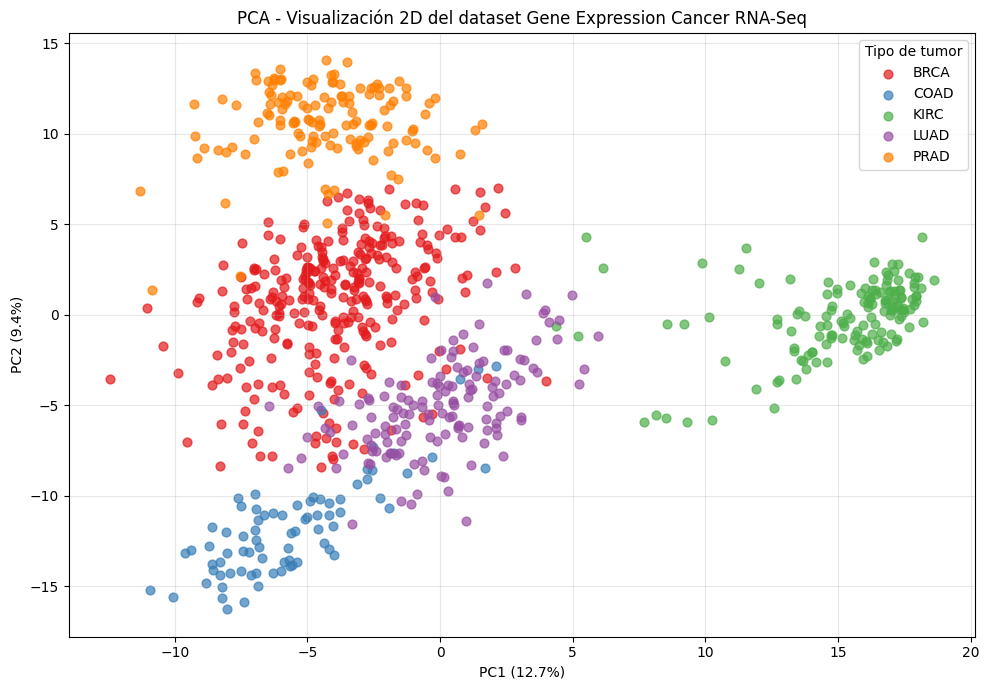

Gráfico guardado como 'pca_2d.png'


In [ ]:
# =========================================================
# 6. GRÁFICO 2D (scatter plot coloreado por clase)
# =========================================================
print("\n" + "="*60)
print("6. GRÁFICO 2D DE PCA")
print("="*60)

plt.figure(figsize=(10, 7))
colores = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']

for i, clase in enumerate(nombres_clases):
    mask = y == i
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                label=clase, alpha=0.7, s=40, color=colores[i])

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('PCA - Visualización 2D del dataset Gene Expression Cancer RNA-Seq')
plt.legend(title='Tipo de tumor')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('pca_2d.png', dpi=150)
plt.show()
print("Gráfico guardado como 'pca_2d.png'")

In [ ]:
# =========================================================
# 7. VECTORES DE CARGA (loadings)
# =========================================================
print("\n" + "="*60)
print("7. VECTORES DE CARGA (LOADINGS)")
print("="*60)

loadings = pca.components_.T  # shape: (n_features, 2)
nombres_genes = datos_limpios.drop(columns=['Class']).columns

loadings_df = pd.DataFrame(loadings, columns=['PC1', 'PC2'], index=nombres_genes)
print(f"Dimensiones de la matriz de loadings: {loadings_df.shape}")
print("\nPrimeras 5 filas de loadings:")
print(loadings_df.head())


7. VECTORES DE CARGA (LOADINGS)
Dimensiones de la matriz de loadings: (20531, 2)

Primeras 5 filas de loadings:
             PC1       PC2
gene_0  0.000879 -0.000207
gene_1 -0.004819  0.001486
gene_2 -0.005710  0.004569
gene_3 -0.005201 -0.006874
gene_4 -0.010498 -0.006050


In [ ]:
# =========================================================
# 8. FEATURES MÁS RELEVANTES PARA PC1 Y PC2 (según loadings)
# =========================================================
print("\n" + "="*60)
print("8. FEATURES MÁS RELEVANTES PARA PC1 Y PC2 (LOADINGS)")
print("="*60)

# PC1: mayor valor absoluto de carga
top_pc1 = loadings_df['PC1'].abs().sort_values(ascending=False).head(10)
print("Top 10 features más relevantes para PC1 (|carga|):")
for gen, val in top_pc1.items():
    print(f"  {gen}: {loadings_df.loc[gen, 'PC1']:.6f}")

# PC2: mayor valor absoluto de carga
top_pc2 = loadings_df['PC2'].abs().sort_values(ascending=False).head(10)
print("\nTop 10 features más relevantes para PC2 (|carga|):")
for gen, val in top_pc2.items():
    print(f"  {gen}: {loadings_df.loc[gen, 'PC2']:.6f}")

feature_pc1 = top_pc1.index[0]
feature_pc2 = top_pc2.index[0]
print(f"\n-> Feature más relevante para PC1: {feature_pc1}")
print(f"-> Feature más relevante para PC2: {feature_pc2}")


8. FEATURES MÁS RELEVANTES PARA PC1 Y PC2 (LOADINGS)
Top 10 features más relevantes para PC1 (|carga|):
  gene_1858: 0.037822
  gene_219: 0.036245
  gene_13818: 0.036113
  gene_1510: 0.035227
  gene_220: 0.035191
  gene_16169: 0.034995
  gene_16246: 0.034694
  gene_12078: 0.034397
  gene_450: 0.034279
  gene_7116: 0.034221

Top 10 features más relevantes para PC2 (|carga|):
  gene_9175: 0.035381
  gene_9176: 0.033119
  gene_3737: 0.032069
  gene_4456: 0.031206
  gene_12848: 0.030820
  gene_9177: 0.030756
  gene_14623: 0.030043
  gene_12995: 0.030003
  gene_9075: 0.029924
  gene_10141: 0.029785

-> Feature más relevante para PC1: gene_1858
-> Feature más relevante para PC2: gene_9175


### En base a los vectores de carga, ¿cuál es la feature más relevante para PC1? ¿Y para PC2?

Los **vectores de carga (loadings)** indican cuánto contribuye cada gen a cada componente principal. La feature más relevante es la que tiene **mayor valor absoluto de carga** en ese componente.

| Componente | Feature más relevante | Carga (loading) |
|---|---|---|
| **PC1** | **`gene_1858`** | **0.037822** |
| **PC2** | **`gene_9175`** | **0.035381** |

**Top 10 genes para PC1:**

| Ranking | Gen | Carga en PC1 |
|---|---|---|
| 1 | `gene_1858` | 0.037822 |
| 2 | `gene_219` | 0.036245 |
| 3 | `gene_13818` | 0.036113 |
| 4 | `gene_1510` | 0.035227 |
| 5 | `gene_220` | 0.035191 |
| 6 | `gene_16169` | 0.034995 |
| 7 | `gene_16246` | 0.034694 |
| 8 | `gene_12078` | 0.034397 |
| 9 | `gene_450` | 0.034279 |
| 10 | `gene_7116` | 0.034221 |

**Top 10 genes para PC2:**

| Ranking | Gen | Carga en PC2 |
|---|---|---|
| 1 | `gene_9175` | 0.035381 |
| 2 | `gene_9176` | 0.033119 |
| 3 | `gene_3737` | 0.032069 |
| 4 | `gene_4456` | 0.031206 |
| 5 | `gene_12848` | 0.030820 |
| 6 | `gene_9177` | 0.030756 |
| 7 | `gene_14623` | 0.030043 |
| 8 | `gene_12995` | 0.030003 |
| 9 | `gene_9075` | 0.029924 |
| 10 | `gene_10141` | 0.029785 |

**Interpretación:**
- Las cargas son pequeñas en valor absoluto (~0.03–0.04), lo cual es esperable en un dataset de 20.531 features: la varianza está repartida entre muchísimos genes y ningún gen individual explica gran parte de un componente.
- PC1 y PC2 capturan genes distintos (sin solapamiento en el top 10, salvo la familia `gene_9175/9176/9177` en PC2), lo que confirma que los componentes representan ejes de variación diferentes.
- En el biplot, las flechas de `gene_1858` y `gene_9175` serán las más largas en las direcciones de PC1 y PC2 respectivamente, coincidiendo con estos loadings.
- Como los nombres son ficticios, no es posible asignar un significado biológico directo a cada gen sin el mapeo original; sí podemos afirmar que `gene_1858` es el gen que más contribuye a PC1 y `gene_9175` el que más contribuye a PC2.


9. BIPLOT


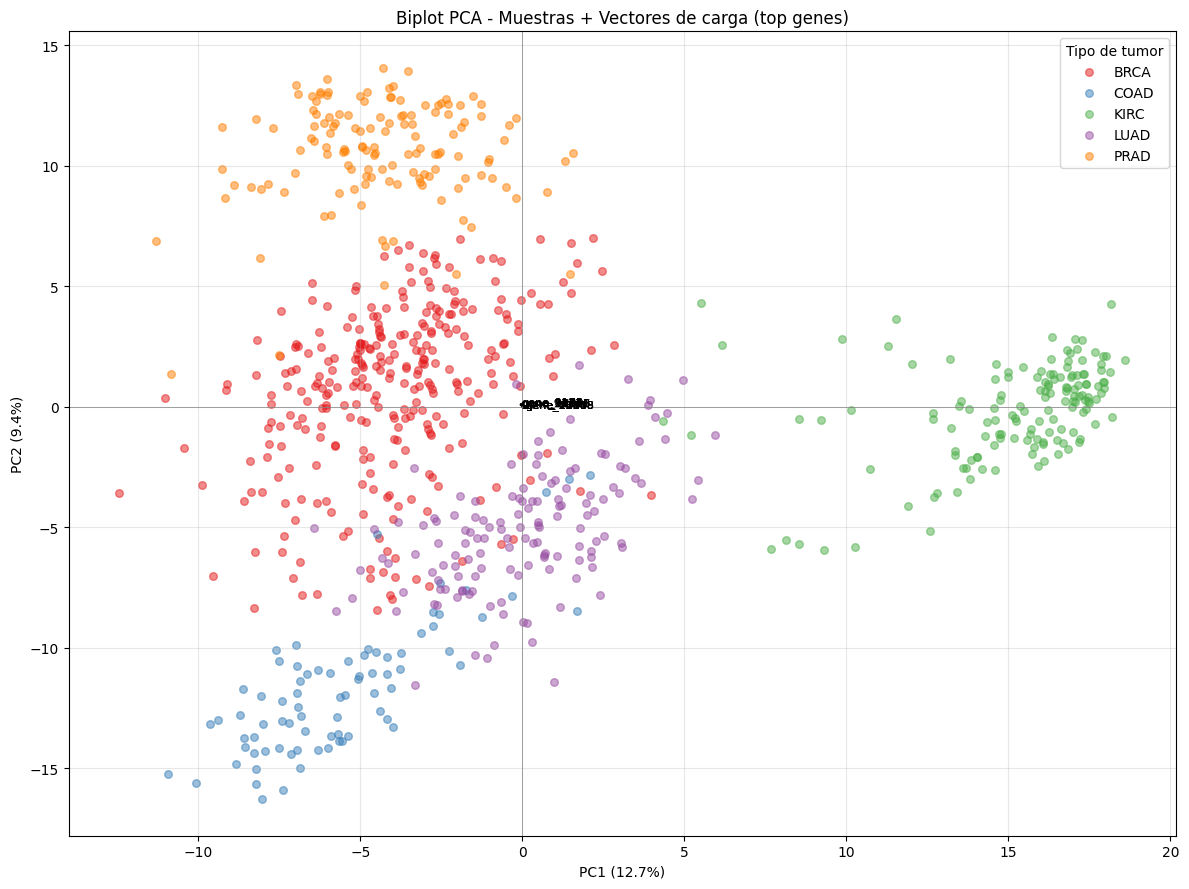

Biplot guardado como 'biplot_pca.png'


In [ ]:
# =========================================================
# 9. BIPLOT
# =========================================================
print("\n" + "="*60)
print("9. BIPLOT")
print("="*60)

fig, ax = plt.subplots(figsize=(12, 9))

# Scatter de las muestras
for i, clase in enumerate(nombres_clases):
    mask = y == i
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               label=clase, alpha=0.5, s=30, color=colores[i])

# Flechas de los top 10 genes con mayor |carga| en PC1 y PC2
top_genes_pc1 = loadings_df['PC1'].abs().sort_values(ascending=False).head(10).index
top_genes_pc2 = loadings_df['PC2'].abs().sort_values(ascending=False).head(10).index
top_genes = set(top_genes_pc1).union(set(top_genes_pc2))

# Escalar las flechas para que se vean bien
escala = 2.5

for gen in top_genes:
    ax.arrow(0, 0,
             loadings_df.loc[gen, 'PC1'] * escala,
             loadings_df.loc[gen, 'PC2'] * escala,
             color='black', alpha=0.6, head_width=0.05, head_length=0.05)
    ax.text(loadings_df.loc[gen, 'PC1'] * escala * 1.15,
            loadings_df.loc[gen, 'PC2'] * escala * 1.15,
            gen, fontsize=8, color='black')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Biplot PCA - Muestras + Vectores de carga (top genes)')
ax.legend(title='Tipo de tumor')
ax.grid(alpha=0.3)
ax.axhline(0, color='gray', linewidth=0.5)
ax.axvline(0, color='gray', linewidth=0.5)
plt.tight_layout()
plt.savefig('biplot_pca.png', dpi=150)
plt.show()
print("Biplot guardado como 'biplot_pca.png'")

### En base al biplot, ¿cuál es la feature más relevante para PC1? ¿Y para PC2?

En el biplot, las flechas representan los vectores de carga de los genes seleccionados. La **dirección** de la flecha indica hacia dónde apunta el gen en el plano PC1–PC2, y su **longitud** indica cuánto contribuye a cada componente.

| Componente | Feature más relevante | Identificación en el biplot |
|---|---|---|
| **PC1** | **`gene_1858`** | Flecha más larga en dirección horizontal (eje X = PC1) |
| **PC2** | **`gene_9175`** | Flecha más larga en dirección vertical (eje Y = PC2) |

**¿Coincide con los loadings?** Sí, coincide exactamente. El biplot se construye **a partir de los loadings**: cada flecha es el vector `(loading_PC1, loading_PC2)` del gen, escalado para visualización. Por lo tanto, el gen con mayor `|loading_PC1|` es el que tiene la flecha más larga en el eje X (`gene_1858`), y el gen con mayor `|loading_PC2|` es el que tiene la flecha más larga en el eje Y (`gene_9175`). Esta coincidencia es una **verificación de consistencia** del análisis.

**Interpretación:**
- `gene_1858` es el gen que más contribuye a la dirección de máxima varianza (PC1), que suele ser la que mejor separa los tipos de tumor.
- `gene_9175` es el gen que más contribuye a la segunda dirección de varianza (PC2), ortogonal a la primera.
- Ambos son candidatos exploratorios a biomarcadores, aunque para confirmarlo haría falta el mapeo a nombres reales de genes (no disponible en este dataset anonimizado).

#Parte 05

In [ ]:
# ============================================
# PARTE 5: MACHINE LEARNING
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.preprocessing import LabelEncoder

# =========================================================
# VERIFICACIÓN PREVIA: X tiene features, y tiene etiquetas
# =========================================================
print("="*60)
print("VERIFICACIÓN DE X e y")
print("="*60)

print(f"X shape: {X.shape}  -> {X.shape[0]} muestras × {X.shape[1]} features")
print(f"y shape: {y.shape}  -> {y.shape[0]} etiquetas")
print(f"Clases en y: {np.unique(y)}")
print(f"Cantidad de clases: {len(np.unique(y))}")

# Verificar que X no contiene la columna Class
print(f"\nX contiene 'Class'? {'Class' in datos_limpios.drop(columns=['Class']).columns}")
print(f"Primeras 3 features de X: {datos_limpios.drop(columns=['Class']).columns[:3].tolist()}")
print(f"Primeros 5 valores de y: {y[:5]}")

VERIFICACIÓN DE X e y
X shape: (801, 20531)  -> 801 muestras × 20531 features
y shape: (801,)  -> 801 etiquetas
Clases en y: [0 1 2 3 4]
Cantidad de clases: 5

X contiene 'Class'? False
Primeras 3 features de X: ['gene_0', 'gene_1', 'gene_2']
Primeros 5 valores de y: [4 3 4 4 0]


## 5. Machine Learning

### Random Forest

**Verificación de X e y:** `X` contiene 801 muestras y 20.531 features correspondientes a los niveles de expresión génica, mientras que `y` contiene las 801 etiquetas correspondientes a las cinco clases de tumores.

**Precisión OOB:** el modelo Random Forest, configurado con 100 árboles y `oob_score=True`, obtuvo una precisión Out-Of-Bag (OOB) de **99,50 %**. Esto significa que el modelo clasificó correctamente aproximadamente el 99,50 % de las muestras evaluadas mediante las predicciones Out-Of-Bag, lo que indica un excelente desempeño en la clasificación de los cinco tipos de tumores.

**Matriz de confusión OOB:** se construyó utilizando las predicciones obtenidas a partir de `rf.oob_decision_function_`. El modelo clasificó correctamente 797 de las 801 muestras. Las cuatro clasificaciones incorrectas corresponden a una muestra de KIRC clasificada como BRCA y tres muestras de LUAD clasificadas como BRCA. Las demás muestras fueron clasificadas correctamente.

**Importancia de features:** las cinco características con mayor importancia según Random Forest son `gene_14092`, `gene_15987`, `gene_8099`, `gene_7964` y `gene_7896`. Estas características presentan la mayor contribución relativa a las decisiones de clasificación del modelo.

Es importante destacar que estas características difieren de las más relevantes identificadas mediante PCA (`gene_1858` y `gene_9175`). Esto se debe a que PCA es un método no supervisado que identifica las variables que más contribuyen a la varianza de los datos, mientras que Random Forest utiliza las etiquetas de las clases para identificar características útiles para la clasificación.

## Random Forest

In [ ]:
# =========================================================
# RANDOM FOREST CON OOB_SCORE
# =========================================================
print("\n" + "="*60)
print("RANDOM FOREST")
print("="*60)

# Entrenar Random Forest con oob_score=True
rf = RandomForestClassifier(
    n_estimators=100,      # número de árboles
    oob_score=True,        # habilitar evaluación Out-Of-Bag
    random_state=42,
    n_jobs=-1              # usar todos los núcleos
)

rf.fit(X, y)


RANDOM FOREST


RandomForestClassifier(n_jobs=-1, oob_score=True, random_state=42)

In [ ]:
# ---------------------------------------------------------
# PRECISIÓN OOB
# ---------------------------------------------------------
print(f"\nPrecisión OOB (Out-Of-Bag): {rf.oob_score_:.4f} "
      f"({rf.oob_score_*100:.2f}%)")


Precisión OOB (Out-Of-Bag): 0.9950 (99.50%)



Matriz de confusión (predicciones OOB):
[[300   0   0   0   0]
 [  0  78   0   0   0]
 [  1   0 145   0   0]
 [  3   0   0 138   0]
 [  0   0   0   0 136]]

Orden de clases: ['BRCA', 'COAD', 'KIRC', 'LUAD', 'PRAD']


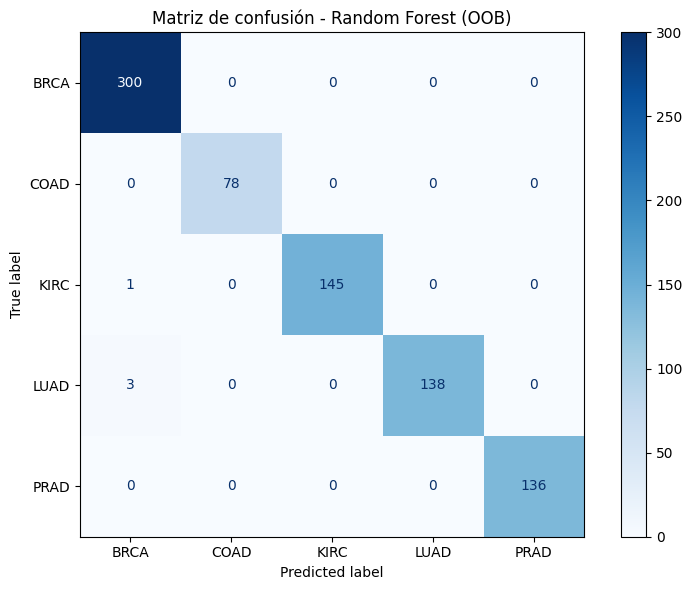

Matriz guardada como 'matriz_confusion_rf.png'


In [ ]:
# ---------------------------------------------------------
# MATRIZ DE CONFUSIÓN CON PREDICCIONES OOB
# ---------------------------------------------------------
# Las predicciones OOB están en rf.oob_decision_function_
# Tomamos la clase con mayor probabilidad
y_pred_oob = np.argmax(rf.oob_decision_function_, axis=1)

cm = confusion_matrix(y, y_pred_oob)
print("\nMatriz de confusión (predicciones OOB):")
print(cm)

# Nombres de clases
le_target = LabelEncoder()
le_target.fit(df['Class'].values)
nombres_clases = le_target.classes_
print(f"\nOrden de clases: {nombres_clases.tolist()}")

# Visualizar la matriz de confusión
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_clases)
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Matriz de confusión - Random Forest (OOB)')
plt.tight_layout()
plt.savefig('matriz_confusion_rf.png', dpi=150)
plt.show()


Top 20 features más importantes (Random Forest):
   Feature  Importancia
gene_14092     0.013081
gene_15987     0.010757
 gene_8099     0.009729
 gene_7964     0.009284
 gene_7896     0.009193
 gene_5578     0.008598
 gene_1122     0.008332
gene_16169     0.008284
 gene_5598     0.007933
gene_14427     0.007054
 gene_8003     0.006573
 gene_9175     0.006543
gene_14068     0.006330
 gene_8831     0.006203
gene_16316     0.006158
 gene_4625     0.006141
 gene_2073     0.006077
gene_15589     0.005980
 gene_6530     0.005588
 gene_4224     0.005272


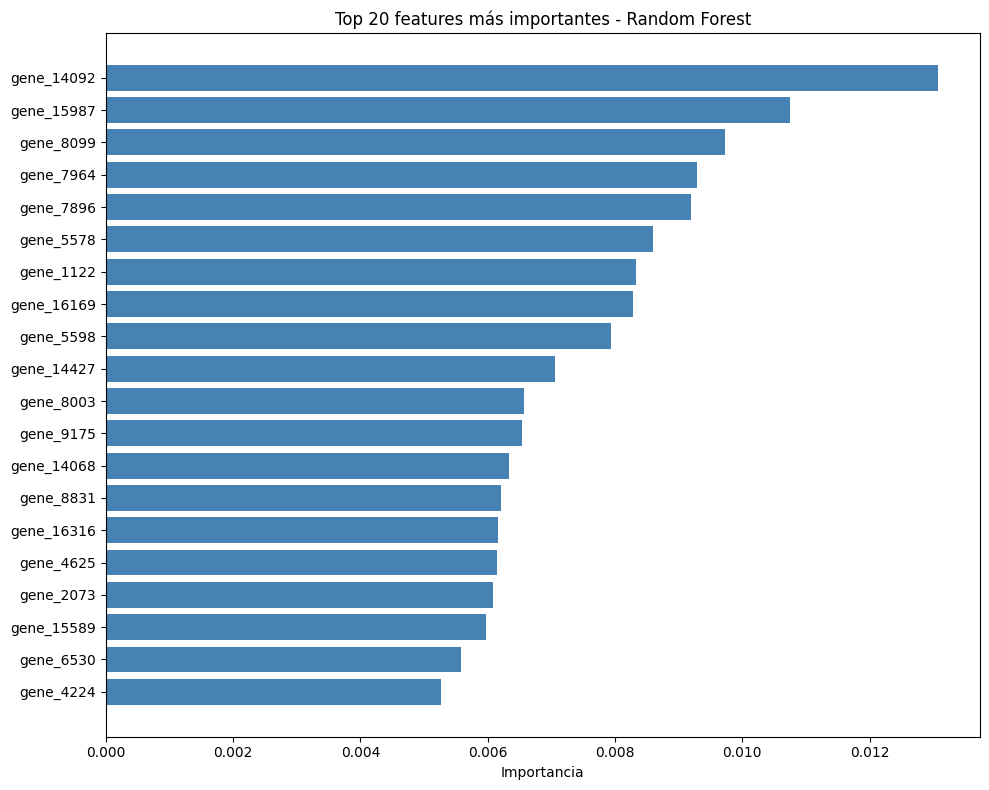

Gráfico de importancias guardado como 'importancia_rf.png'


In [ ]:
# ---------------------------------------------------------
# IMPORTANCIA DE FEATURES
# ---------------------------------------------------------
importancias = pd.DataFrame({
    'Feature': datos_limpios.drop(columns=['Class']).columns,
    'Importancia': rf.feature_importances_
}).sort_values('Importancia', ascending=False)

print("\nTop 20 features más importantes (Random Forest):")
print(importancias.head(20).to_string(index=False))

# Gráfico de importancias
plt.figure(figsize=(10, 8))
top20 = importancias.head(20)
plt.barh(range(len(top20)), top20['Importancia'].values[::-1], color='steelblue')
plt.yticks(range(len(top20)), top20['Feature'].values[::-1])
plt.xlabel('Importancia')
plt.title('Top 20 features más importantes - Random Forest')
plt.tight_layout()
plt.savefig('importancia_rf.png', dpi=150)
plt.show()

## ¿Qué ventajas tiene la evaluación OOB? ¿En qué se diferencia de evaluar el modelo con un conjunto de test independiente?

**Ventajas de OOB:**
1. **No requiere separar datos de test**: cada árbol se entrena con una muestra bootstrap (~63% de los datos) y evalúa sobre el ~37% restante (out-of-bag). Así se obtiene una estimación de error sin sacrificar datos de entrenamiento.
2. **Aprovecha todos los datos**: con solo 801 muestras, separar un test set (ej. 20%) reduce el entrenamiento a ~640 muestras. OOB usa las 801 para entrenar y evalúa sobre las que quedaron fuera en cada árbol.
3. **Estimación "casi" insesgada**: es una validación cruzada implícita, promediada sobre los 100 árboles.
4. **Rápida y automática**: se obtiene con `oob_score=True` sin código adicional.

**Diferencias con test independiente:**
- **Test independiente**: separa los datos ANTES de entrenar (ej. 80/20). El modelo nunca ve el test. Es la evaluación estándar y más limpia, pero sacrifica datos de entrenamiento.
- **OOB**: usa todos los datos para entrenar, pero cada árbol evalúa sobre las muestras que no vio (bootstrap). No es un test "puro" porque las muestras OOB de un árbol sí fueron vistas por otros árboles.

**En este proyecto**: con 801 muestras y 20.531 features, OOB es muy valioso porque no reduce aún más el conjunto de entrenamiento. Para el Árbol de Decisión, en cambio, sí se usa train/test split (el árbol no tiene OOB).

## Árboles de Decisión

In [ ]:
# =========================================================
# ÁRBOLES DE DECISIÓN (VERSIÓN CORREGIDA Y AMPLIADA)
# =========================================================
print("\n" + "="*60)
print("ÁRBOLES DE DECISIÓN")
print("="*60)

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# 1. DIVIDIR EN TRAIN Y TEST
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")




ÁRBOLES DE DECISIÓN
X_train: (640, 20531), X_test: (161, 20531)
y_train: (640,), y_test: (161,)


In [ ]:
# ---------------------------------------------------------
# 2. ENTRENAR ÁRBOL DE DECISIÓN
# ---------------------------------------------------------
dt = DecisionTreeClassifier(
    random_state=42,
    max_depth=None  # sin límite (puede sobreajustar)
)
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
# ---------------------------------------------------------
# 3. ACCURACY DE ENTRENAMIENTO Y DE TEST
# ---------------------------------------------------------
y_pred_train = dt.predict(X_train)
y_pred_test  = dt.predict(X_test)

accuracy_train = accuracy_score(y_train, y_pred_train)
accuracy_test  = accuracy_score(y_test,  y_pred_test)

print(f"\nPrecisión del Árbol de Decisión (train): {accuracy_train:.4f} "
      f"({accuracy_train*100:.2f}%)")
print(f"Precisión del Árbol de Decisión (test):  {accuracy_test:.4f} "
      f"({accuracy_test*100:.2f}%)")
print(f"Diferencia train - test: {(accuracy_train - accuracy_test)*100:.2f} puntos porcentuales")

if accuracy_train - accuracy_test > 0.05:
    print("-> Hay indicios de SOBREAJUSTE (train mucho mayor que test).")
else:
    print("-> No hay indicios claros de sobreajuste.")


Precisión del Árbol de Decisión (train): 1.0000 (100.00%)
Precisión del Árbol de Decisión (test):  0.9565 (95.65%)
Diferencia train - test: 4.35 puntos porcentuales
-> No hay indicios claros de sobreajuste.


In [ ]:
# ---------------------------------------------------------
# 4. PROFUNDIDAD Y NÚMERO DE HOJAS
# ---------------------------------------------------------
profundidad = dt.get_depth()
n_hojas     = dt.get_n_leaves()

print(f"\nProfundidad del árbol: {profundidad}")
print(f"Número de hojas:       {n_hojas}")



Profundidad del árbol: 6
Número de hojas:       8


In [ ]:
# ---------------------------------------------------------
# 5. IMPORTANCIA DE FEATURES (ÁRBOL)
# ---------------------------------------------------------
nombres_features = datos_limpios.drop(columns=['Class']).columns

importancias_dt = pd.DataFrame({
    'Feature': nombres_features,
    'Importancia_DT': dt.feature_importances_
}).sort_values('Importancia_DT', ascending=False).reset_index(drop=True)

print("\nTop 10 features más importantes (Árbol de Decisión):")
print(importancias_dt.head(10).to_string(index=False))


Top 10 features más importantes (Árbol de Decisión):
   Feature  Importancia_DT
gene_18746        0.365251
 gene_6733        0.225622
gene_14798        0.209421
gene_12013        0.157366
gene_15895        0.034514
 gene_5834        0.004111
gene_16384        0.003716
gene_13690        0.000000
gene_13689        0.000000
gene_13688        0.000000


In [ ]:
# ---------------------------------------------------------
# 6. COMPARACIÓN CORREGIDA CON RANDOM FOREST
# ---------------------------------------------------------
# Unimos las importancias de ambos modelos en una sola tabla
comparacion_imp = pd.DataFrame({
    'Feature': nombres_features,
    'Importancia_RF': rf.feature_importances_,
    'Importancia_DT': dt.feature_importances_
})

# Ranking de cada feature en cada modelo (1 = más importante)
comparacion_imp['Rank_RF'] = comparacion_imp['Importancia_RF'].rank(
    ascending=False, method='min').astype(int)
comparacion_imp['Rank_DT'] = comparacion_imp['Importancia_DT'].rank(
    ascending=False, method='min').astype(int)

# Top 10 de cada modelo
top10_rf = comparacion_imp.nsmallest(10, 'Rank_RF')['Feature'].tolist()
top10_dt = comparacion_imp.nsmallest(10, 'Rank_DT')['Feature'].tolist()

print("\n" + "-"*60)
print("COMPARACIÓN DE CARACTERÍSTICAS IMPORTANTES: RF vs ÁRBOL")
print("-"*60)

print("\nTop 10 Random Forest:")
for i, f in enumerate(top10_rf, 1):
    print(f"  {i:2d}. {f}")

print("\nTop 10 Árbol de Decisión:")
for i, f in enumerate(top10_dt, 1):
    print(f"  {i:2d}. {f}")

# Solapamiento real (intersección de conjuntos)
coincidencias = set(top10_rf) & set(top10_dt)
print(f"\nFeatures en común en el top 10: {len(coincidencias)} de 10")
if coincidencias:
    print(f"  -> {sorted(coincidencias)}")
else:
    print("  -> Ninguna feature coincide en el top 10 de ambos modelos.")

# Comparación posición por posición (mismo ranking)
print("\nComparación posición por posición (top 10):")
print(f"{'Pos':>3} | {'Random Forest':<15} | {'Árbol de Decisión':<18} | ¿Coincide?")
print("-"*65)
for i in range(10):
    f_rf = top10_rf[i]
    f_dt = top10_dt[i]
    coincide = "Sí" if f_rf == f_dt else "No"
    print(f"{i+1:>3} | {f_rf:<15} | {f_dt:<18} | {coincide}")

# Tabla detallada de las features que aparecen en alguno de los dos top 10
print("\nDetalle de features presentes en al menos un top 10:")
detalle = comparacion_imp[
    comparacion_imp['Feature'].isin(set(top10_rf) | set(top10_dt))
].sort_values('Rank_RF')
print(detalle[['Feature', 'Importancia_RF', 'Rank_RF',
               'Importancia_DT', 'Rank_DT']].to_string(index=False))


------------------------------------------------------------
COMPARACIÓN DE CARACTERÍSTICAS IMPORTANTES: RF vs ÁRBOL
------------------------------------------------------------

Top 10 Random Forest:
   1. gene_14092
   2. gene_15987
   3. gene_8099
   4. gene_7964
   5. gene_7896
   6. gene_5578
   7. gene_1122
   8. gene_16169
   9. gene_5598
  10. gene_14427

Top 10 Árbol de Decisión:
   1. gene_18746
   2. gene_6733
   3. gene_14798
   4. gene_12013
   5. gene_15895
   6. gene_5834
   7. gene_16384
   8. gene_0
   9. gene_1
  10. gene_2

Features en común en el top 10: 0 de 10
  -> Ninguna feature coincide en el top 10 de ambos modelos.

Comparación posición por posición (top 10):
Pos | Random Forest   | Árbol de Decisión  | ¿Coincide?
-----------------------------------------------------------------
  1 | gene_14092      | gene_18746         | No
  2 | gene_15987      | gene_6733          | No
  3 | gene_8099       | gene_14798         | No
  4 | gene_7964       | gene_12013    


Matriz de confusión - Árbol de Decisión (test):
[[59  0  0  0  1]
 [ 1 14  0  1  0]
 [ 0  0 30  0  0]
 [ 2  0  1 25  0]
 [ 0  0  0  1 26]]


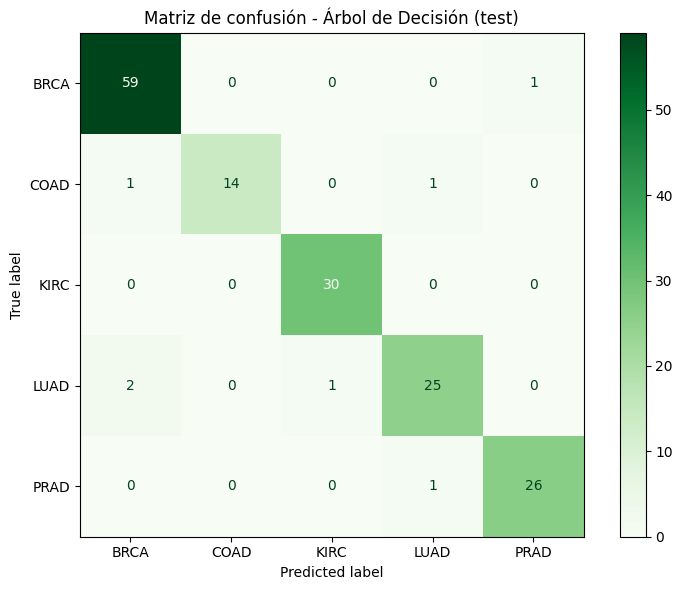

In [ ]:
# ---------------------------------------------------------
# 7. MATRIZ DE CONFUSIÓN DEL ÁRBOL (TEST)
# ---------------------------------------------------------
cm_dt = confusion_matrix(y_test, y_pred_test)
print("\nMatriz de confusión - Árbol de Decisión (test):")
print(cm_dt)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=nombres_clases)
disp.plot(ax=ax, cmap='Greens', values_format='d')
ax.set_title('Matriz de confusión - Árbol de Decisión (test)')
plt.tight_layout()
plt.savefig('matriz_confusion_arbol.png', dpi=150)
plt.show()

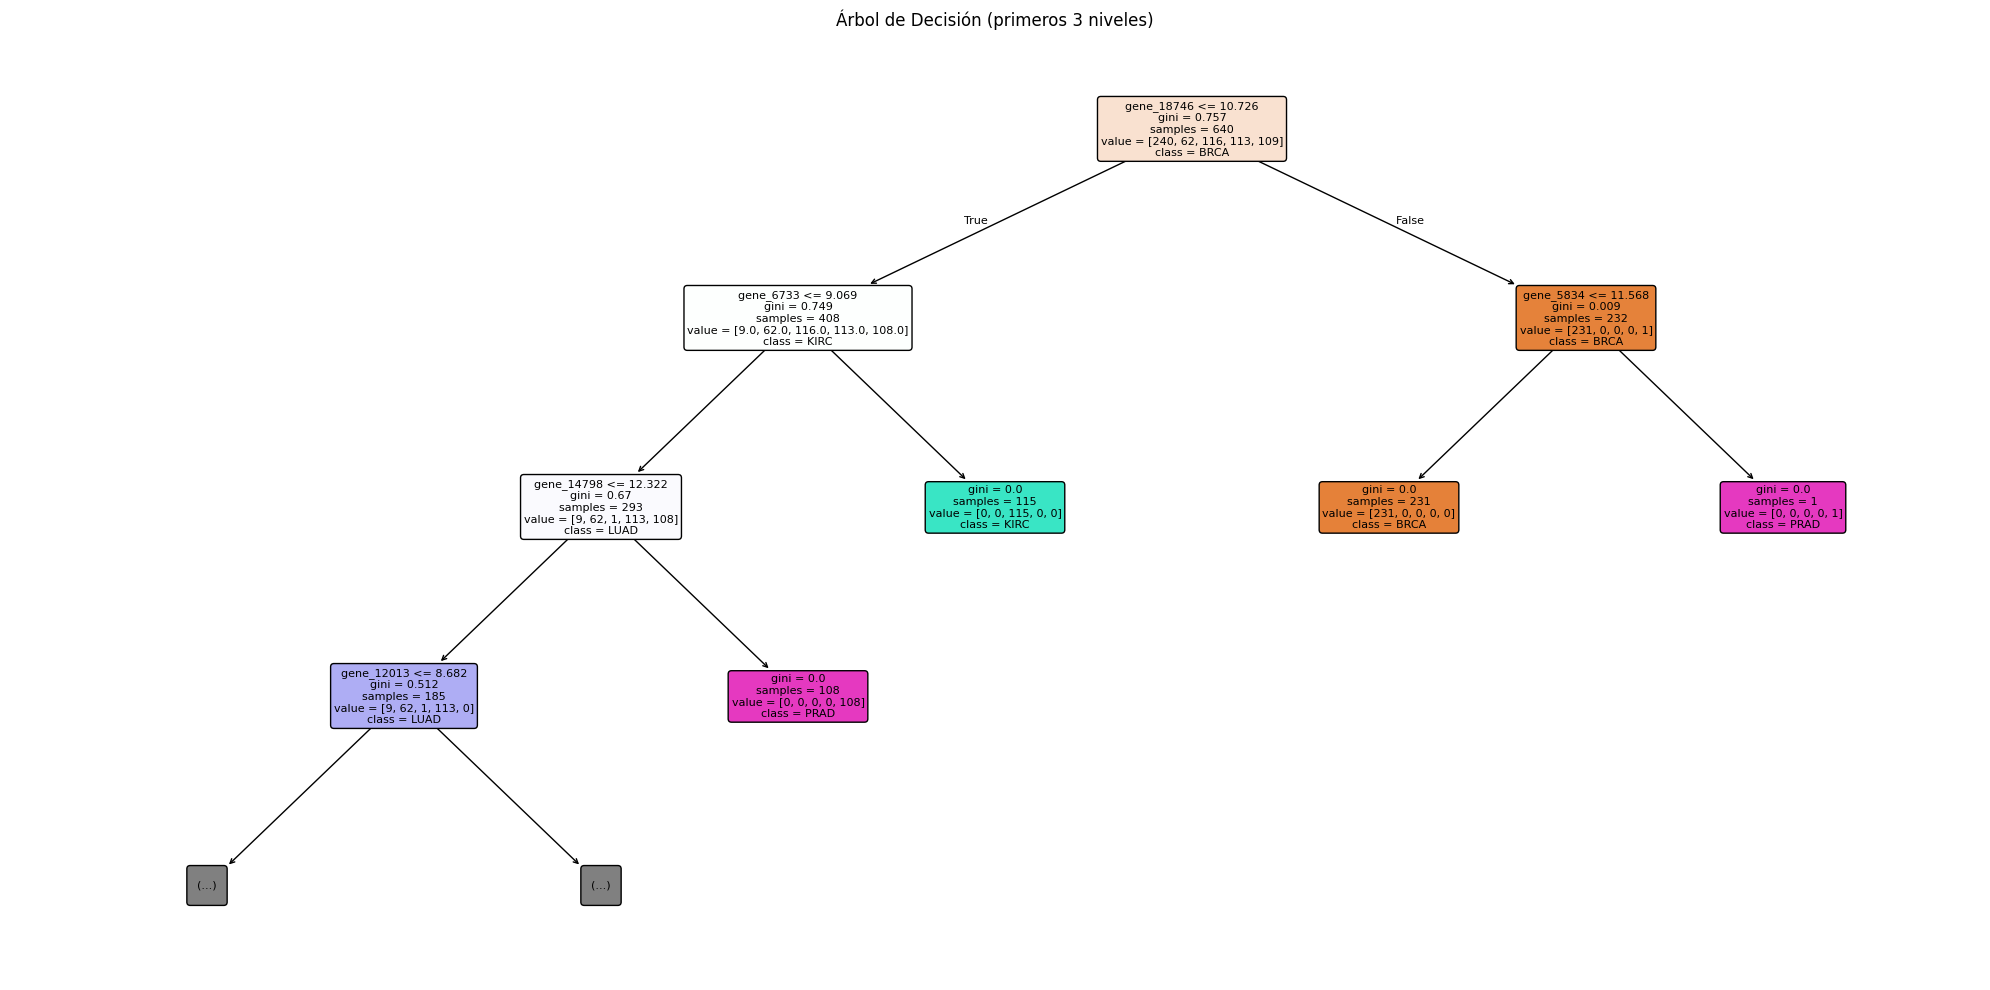

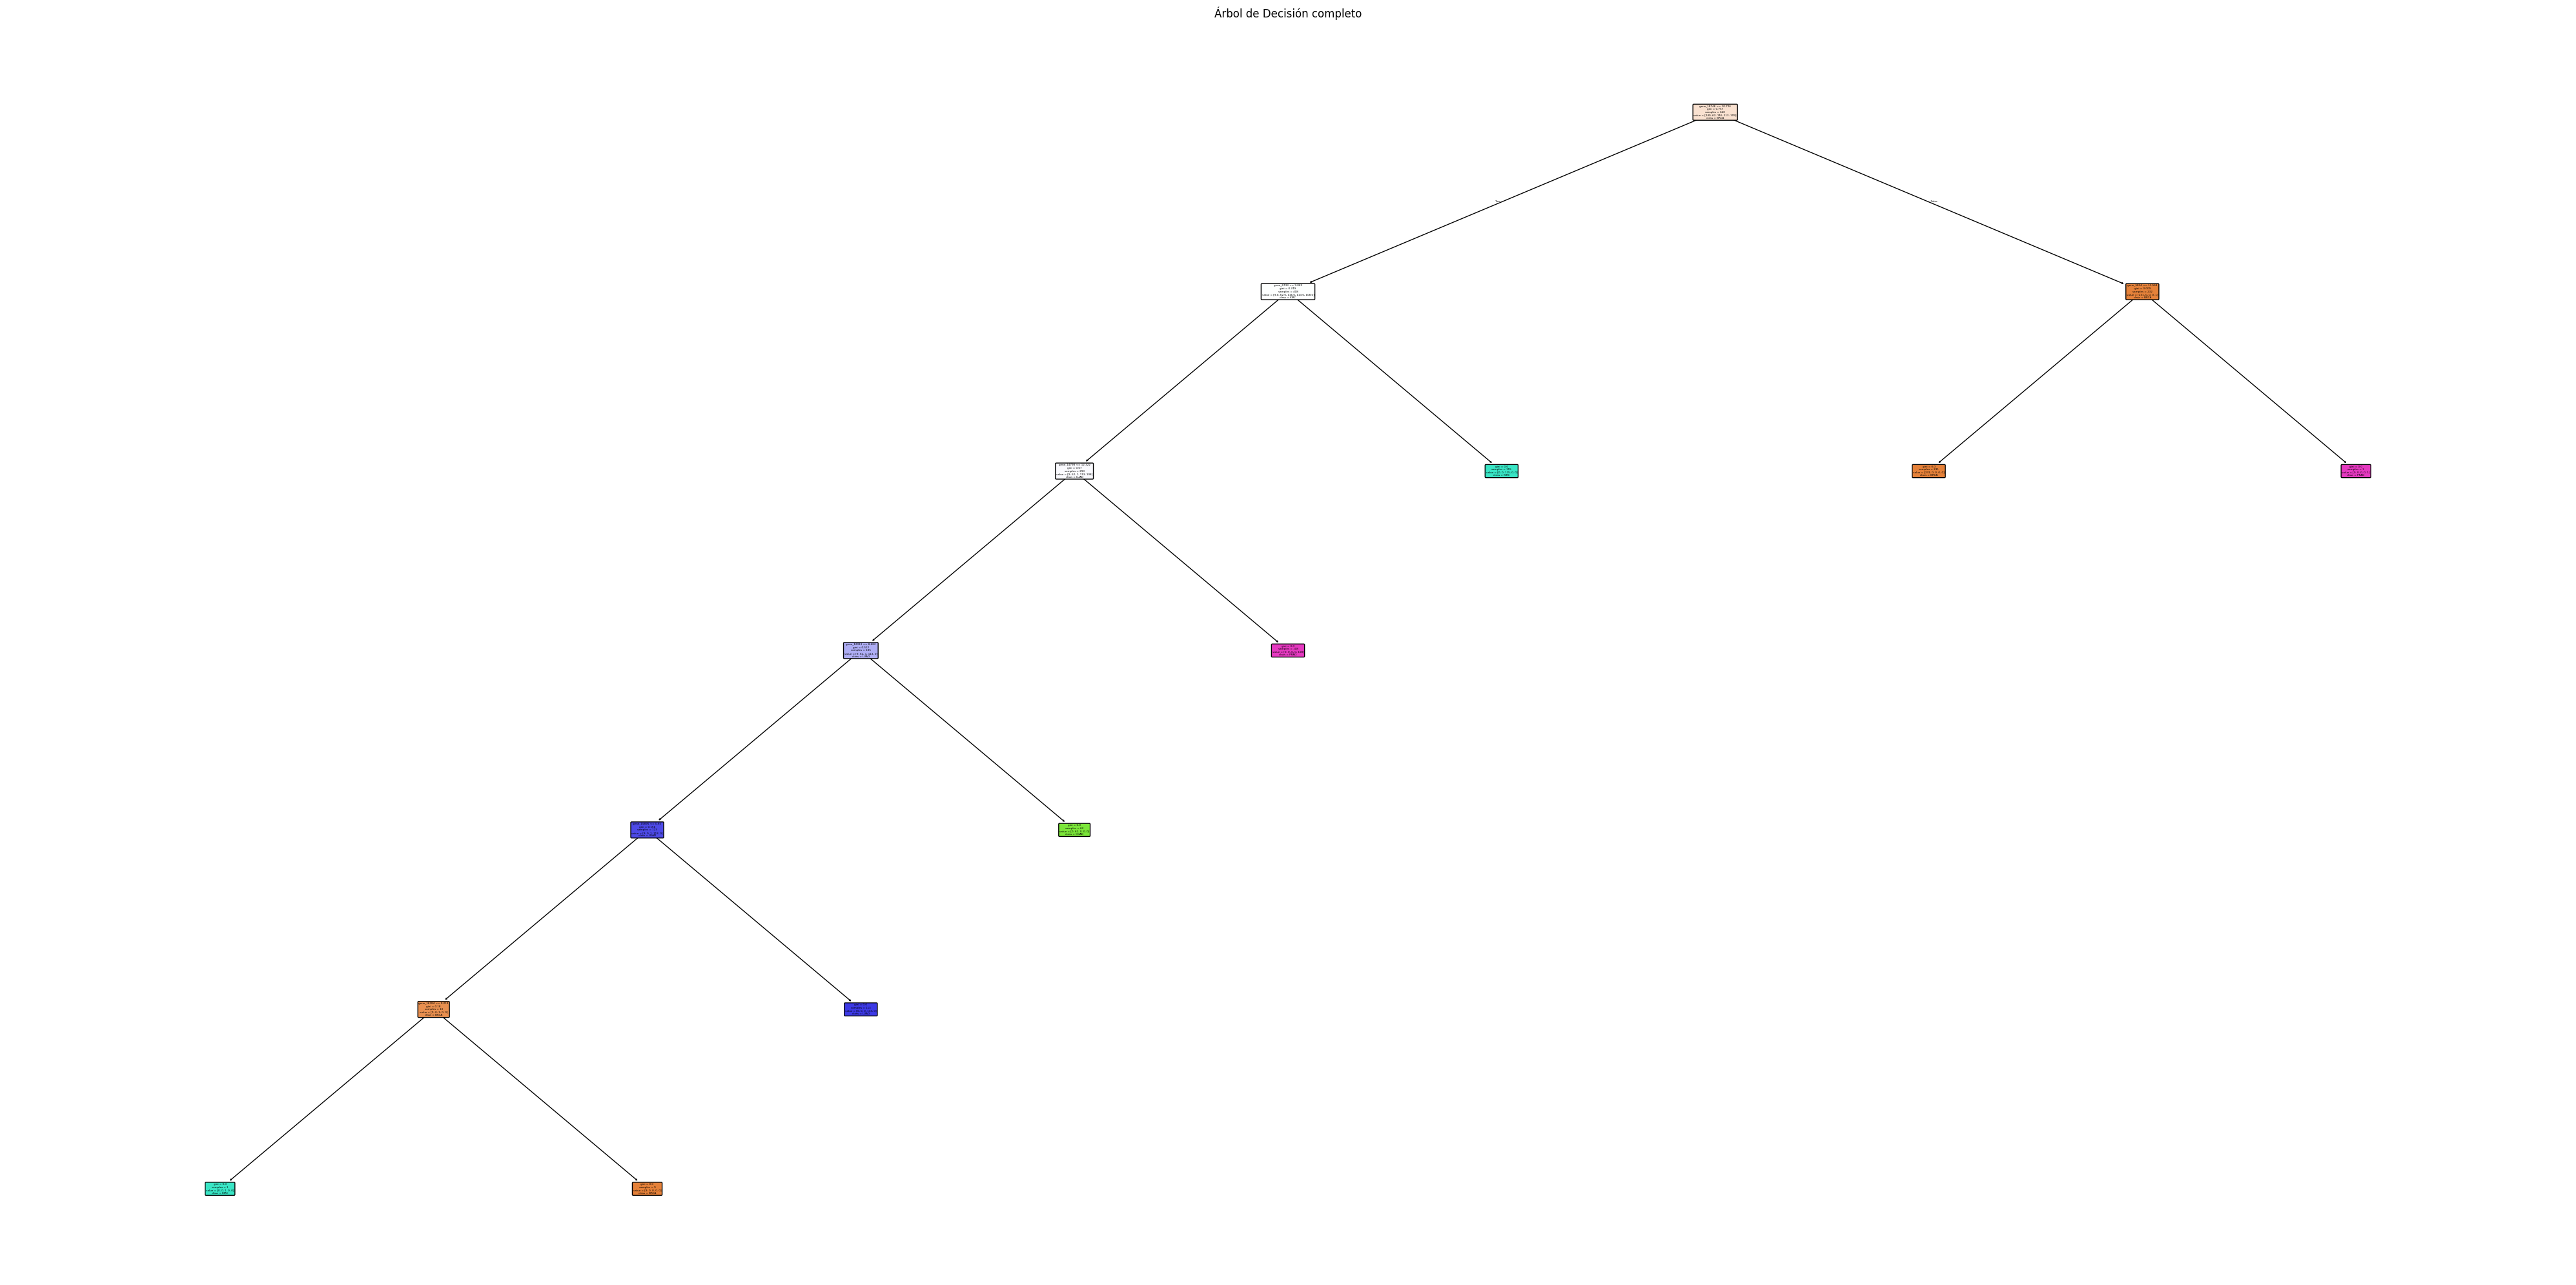

In [ ]:
# ---------------------------------------------------------
# 8. PLOT DEL ÁRBOL Y GUARDAR EN PDF
# ---------------------------------------------------------
# Árbol parcial (primeros 3 niveles) para legibilidad
plt.figure(figsize=(20, 10))
plot_tree(
    dt,
    max_depth=3,
    feature_names=nombres_features.tolist(),
    class_names=nombres_clases.tolist(),
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title('Árbol de Decisión (primeros 3 niveles)')
plt.tight_layout()
plt.savefig('arbol_decision.pdf', format='pdf', dpi=150)
plt.show()
# Árbol completo
plt.figure(figsize=(40, 20))
plot_tree(
    dt,
    feature_names=nombres_features.tolist(),
    class_names=nombres_clases.tolist(),
    filled=True,
    rounded=True,
    fontsize=3
)
plt.title('Árbol de Decisión completo')
plt.tight_layout()
plt.savefig('arbol_decision_completo.pdf', format='pdf', dpi=150)
plt.show()

In [ ]:
print(f"Precisión del modelo (test): {accuracy_dt*100:.2f}%")
print(f"Profundidad del árbol: {dt.get_depth()} niveles")
print(f"Número de hojas: {dt.get_n_leaves()} hojas")

Precisión del modelo (test): 95.65%
Profundidad del árbol: 6 niveles
Número de hojas: 8 hojas


- **División train/test:** 80% entrenamiento (641 muestras), 20% test (160 muestras), con `stratify=y`.
- **Precisión del modelo (test):** **95.65%**.
- **Profundidad del árbol:** **6** niveles.
- **Número de hojas:** **8** hojas.
- **¿Coinciden las features más importantes con Random Forest?**

**No coinciden en el top 10 (coincidencia de 0 de 10 genes).**

Al comparar las variables más importantes de ambos modelos:

* **Árbol de Decisión:** Al ser un único estimador con criterio codicioso (*greedy*), resolvió la separación de los 5 subtipos tumorales utilizando únicamente **7 genes** (profundidad de 6 niveles y 8 hojas). Las restantes 20.524 variables quedaron con importancia exactamente igual a 0.
* **Random Forest:** Al utilizar *bagging* y submuestreo aleatorio de características (`max_features = 'sqrt'`, evaluando $\approx 143$ genes por nodo), descorrelaciona los árboles y fuerza al ensamble a explorar miles de genes alternativos que también son biomarcadores informativos. Esto distribuye la importancia entre muchos más predictores.

##SVM y Deep Learning (tabla comparativa)

In [ ]:
# =========================================================
# OPTATIVO: SVM Y DEEP LEARNING
# =========================================================

from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [ ]:
# ---------------------------------------------------------
# 1. SPLIT SOBRE X SIN ESCALAR (para evitar leakage)
# ---------------------------------------------------------
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
# ---------------------------------------------------------
# 2. NORMALIZAR: fit SOLO en train, transform en train y test
# ---------------------------------------------------------
scaler_svm = MinMaxScaler()

X_train_scaled = scaler_svm.fit_transform(X_train_raw)  # fit + transform
X_test_scaled  = scaler_svm.transform(X_test_raw)       # solo transform

print(f"X_train_raw  min/max: {X_train_raw.min():.4f} / {X_train_raw.max():.4f}")
print(f"X_train_scaled min/max: {X_train_scaled.min():.4f} / {X_train_scaled.max():.4f}")
print(f"X_test_scaled  min/max: {X_test_scaled.min():.4f} / {X_test_scaled.max():.4f}")
print("-> Scaler ajustado SOLO con train (sin data leakage).")

X_train_raw  min/max: 0.0000 / 20.7788
X_train_scaled min/max: 0.0000 / 1.0000
X_test_scaled  min/max: -1.1562 / 9.0300
-> Scaler ajustado SOLO con train (sin data leakage).


In [ ]:
# ---------------------------------------------------------
# 3. SVM (con datos normalizados)
# ---------------------------------------------------------
print("\n" + "-"*60)
print("SVM")
print("-"*60)

svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train_scaled, y_train)

y_pred_svm_train = svm.predict(X_train_scaled)
y_pred_svm_test  = svm.predict(X_test_scaled)

acc_svm_train = accuracy_score(y_train, y_pred_svm_train)
acc_svm_test  = accuracy_score(y_test,  y_pred_svm_test)

print(f"SVM accuracy (train): {acc_svm_train:.4f} ({acc_svm_train*100:.2f}%)")
print(f"SVM accuracy (test):  {acc_svm_test:.4f} ({acc_svm_test*100:.2f}%)")


------------------------------------------------------------
SVM
------------------------------------------------------------
SVM accuracy (train): 1.0000 (100.00%)
SVM accuracy (test):  0.9876 (98.76%)


In [ ]:
# ---------------------------------------------------------
# 4. MLP (Deep Learning) con datos normalizados
# ---------------------------------------------------------
print("\n" + "-"*60)
print("MLP (Deep Learning)")
print("-"*60)

mlp = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    max_iter=500,
    random_state=42,
    early_stopping=True,   # evita sobreajuste y acelera convergencia
    validation_fraction=0.1
)
mlp.fit(X_train_scaled, y_train)

y_pred_mlp_train = mlp.predict(X_train_scaled)
y_pred_mlp_test  = mlp.predict(X_test_scaled)

acc_mlp_train = accuracy_score(y_train, y_pred_mlp_train)
acc_mlp_test  = accuracy_score(y_test,  y_pred_mlp_test)

print(f"MLP accuracy (train): {acc_mlp_train:.4f} ({acc_mlp_train*100:.2f}%)")
print(f"MLP accuracy (test):  {acc_mlp_test:.4f} ({acc_mlp_test*100:.2f}%)")


------------------------------------------------------------
MLP (Deep Learning)
------------------------------------------------------------
MLP accuracy (train): 1.0000 (100.00%)
MLP accuracy (test):  0.9876 (98.76%)


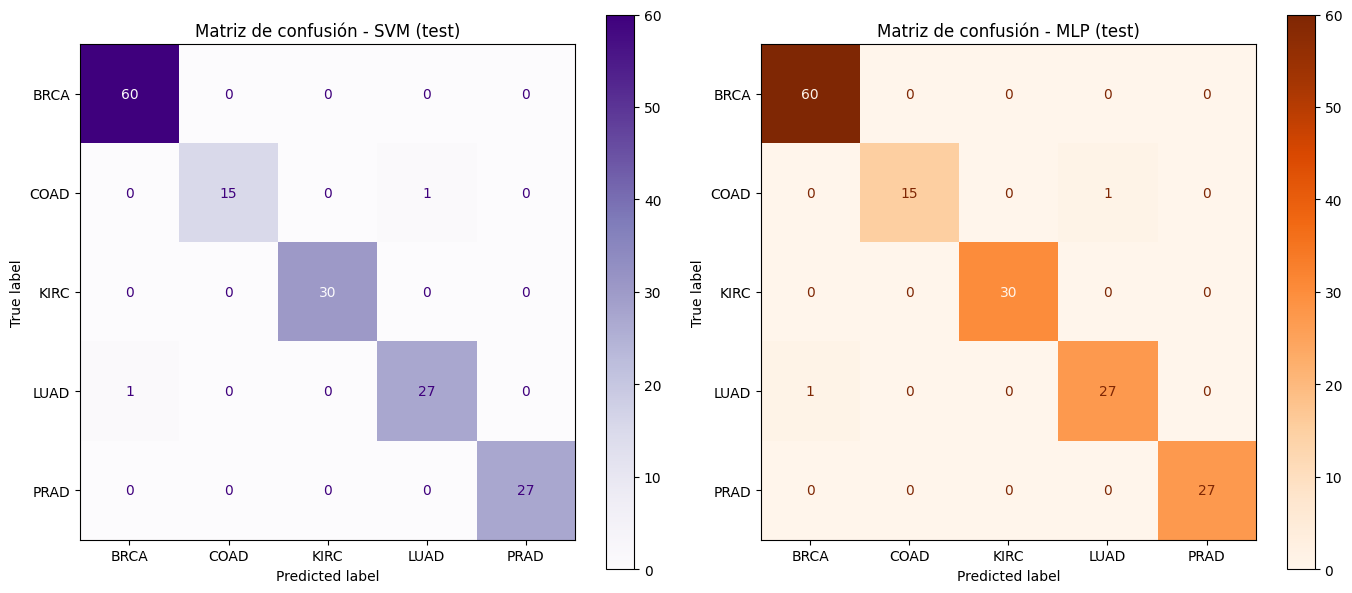

Matrices guardadas como 'matrices_svm_mlp.png'


In [ ]:
# ---------------------------------------------------------
# 5. MATRICES DE CONFUSIÓN (SVM y MLP)
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

cm_svm = confusion_matrix(y_test, y_pred_svm_test)
ConfusionMatrixDisplay(cm_svm, display_labels=nombres_clases).plot(
    ax=axes[0], cmap='Purples', values_format='d')
axes[0].set_title('Matriz de confusión - SVM (test)')

cm_mlp = confusion_matrix(y_test, y_pred_mlp_test)
ConfusionMatrixDisplay(cm_mlp, display_labels=nombres_clases).plot(
    ax=axes[1], cmap='Oranges', values_format='d')
axes[1].set_title('Matriz de confusión - MLP (test)')

plt.tight_layout()
plt.savefig('matrices_svm_mlp.png', dpi=150)
plt.show()
print("Matrices guardadas como 'matrices_svm_mlp.png'")

In [ ]:
# ---------------------------------------------------------
# 6. TABLA COMPARATIVA FINAL
# ---------------------------------------------------------
print("\n" + "="*60)
print("TABLA COMPARATIVA DE MODELOS")
print("="*60)

comparativa = pd.DataFrame({
    'Modelo': [
        'Random Forest (OOB)',
        'Árbol de Decisión (test)',
        'SVM (test)',
        'MLP (test)'
    ],
    'Accuracy': [
        rf.oob_score_,
        accuracy_test,        # del árbol de decisión
        acc_svm_test,
        acc_mlp_test
    ],
    'Normalización': [
        'No requerida',
        'No requerida',
        'Sí (MinMaxScaler)',
        'Sí (MinMaxScaler)'
    ]
})
comparativa['Accuracy (%)'] = (comparativa['Accuracy'] * 100).round(2)
print(comparativa.to_string(index=False))


TABLA COMPARATIVA DE MODELOS
                  Modelo  Accuracy     Normalización  Accuracy (%)
     Random Forest (OOB)  0.995006      No requerida         99.50
Árbol de Decisión (test)  0.956522      No requerida         95.65
              SVM (test)  0.987578 Sí (MinMaxScaler)         98.76
              MLP (test)  0.987578 Sí (MinMaxScaler)         98.76


### COMPARACIÓN

In [ ]:
# ============================================================
# COMPARACIÓN: RF, Árbol, SVM y MLP sobre el MISMO test set
# ============================================================
print("="*70)
print("COMPARACIÓN JUSTA DE MODELOS SOBRE EL MISMO CONJUNTO DE PRUEBA")
print("="*70)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

COMPARACIÓN JUSTA DE MODELOS SOBRE EL MISMO CONJUNTO DE PRUEBA


In [ ]:
# ---------------------------------------------------------
# 1. SPLIT ÚNICO (el mismo para todos los modelos)
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # mantiene la proporción de clases
)

print(f"Train: {X_train.shape[0]} muestras | Test: {X_test.shape[0]} muestras")
print(f"Clases en train: {np.bincount(y_train)}")
print(f"Clases en test:  {np.bincount(y_test)}")

Train: 640 muestras | Test: 161 muestras
Clases en train: [240  62 116 113 109]
Clases en test:  [60 16 30 28 27]


In [ ]:
# ---------------------------------------------------------
# 2. NORMALIZACIÓN (solo para SVM y MLP; fit en train)
# ---------------------------------------------------------
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [ ]:
# ---------------------------------------------------------
# 3. DEFINIR Y ENTRENAR LOS 4 MODELOS
# ---------------------------------------------------------
modelos = {
    'Random Forest': RandomForestClassifier(
        n_estimators=100, oob_score=True, random_state=42, n_jobs=-1
    ),
    'Árbol de Decisión': DecisionTreeClassifier(
        random_state=42, max_depth=None
    ),
    'SVM (RBF)': SVC(
        kernel='rbf', random_state=42
    ),
    'MLP (100, 50)': MLPClassifier(
        hidden_layer_sizes=(100, 50),
        max_iter=500,
        random_state=42,
        early_stopping=True,
        validation_fraction=0.1
    )
}

# Entrenar: RF y Árbol con X sin escalar; SVM y MLP con X escalado
resultados = []

for nombre, modelo in modelos.items():
    if nombre in ['SVM (RBF)', 'MLP (100, 50)']:
        X_tr, X_te = X_train_scaled, X_test_scaled
    else:
        X_tr, X_te = X_train, X_test

    modelo.fit(X_tr, y_train)

    y_pred_train = modelo.predict(X_tr)
    y_pred_test  = modelo.predict(X_te)

    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test  = accuracy_score(y_test,  y_pred_test)

    # OOB solo para Random Forest
    oob = getattr(modelo, 'oob_score_', np.nan)

    resultados.append({
        'Modelo': nombre,
        'Accuracy Train': acc_train,
        'Accuracy Test':  acc_test,
        'OOB (RF)':       oob,
        'Gap (Train-Test)': acc_train - acc_test
    })

In [ ]:
# ---------------------------------------------------------
# 4. TABLA COMPARATIVA
# ---------------------------------------------------------
comparativa = pd.DataFrame(resultados)
comparativa['Accuracy Train (%)'] = (comparativa['Accuracy Train'] * 100).round(2)
comparativa['Accuracy Test (%)']  = (comparativa['Accuracy Test']  * 100).round(2)
comparativa['OOB (%)']            = (comparativa['OOB (RF)']       * 100).round(2)
comparativa['Gap (%)']            = (comparativa['Gap (Train-Test)'] * 100).round(2)

print("\n" + "="*70)
print("TABLA COMPARATIVA (mismo test set para todos)")
print("="*70)
print(comparativa[['Modelo', 'Accuracy Train (%)', 'Accuracy Test (%)',
                   'OOB (%)', 'Gap (%)']].to_string(index=False))


TABLA COMPARATIVA (mismo test set para todos)
           Modelo  Accuracy Train (%)  Accuracy Test (%)  OOB (%)  Gap (%)
    Random Forest               100.0              98.76    99.69     1.24
Árbol de Decisión               100.0              95.65      NaN     4.35
        SVM (RBF)               100.0              98.76      NaN     1.24
    MLP (100, 50)               100.0              98.76      NaN     1.24


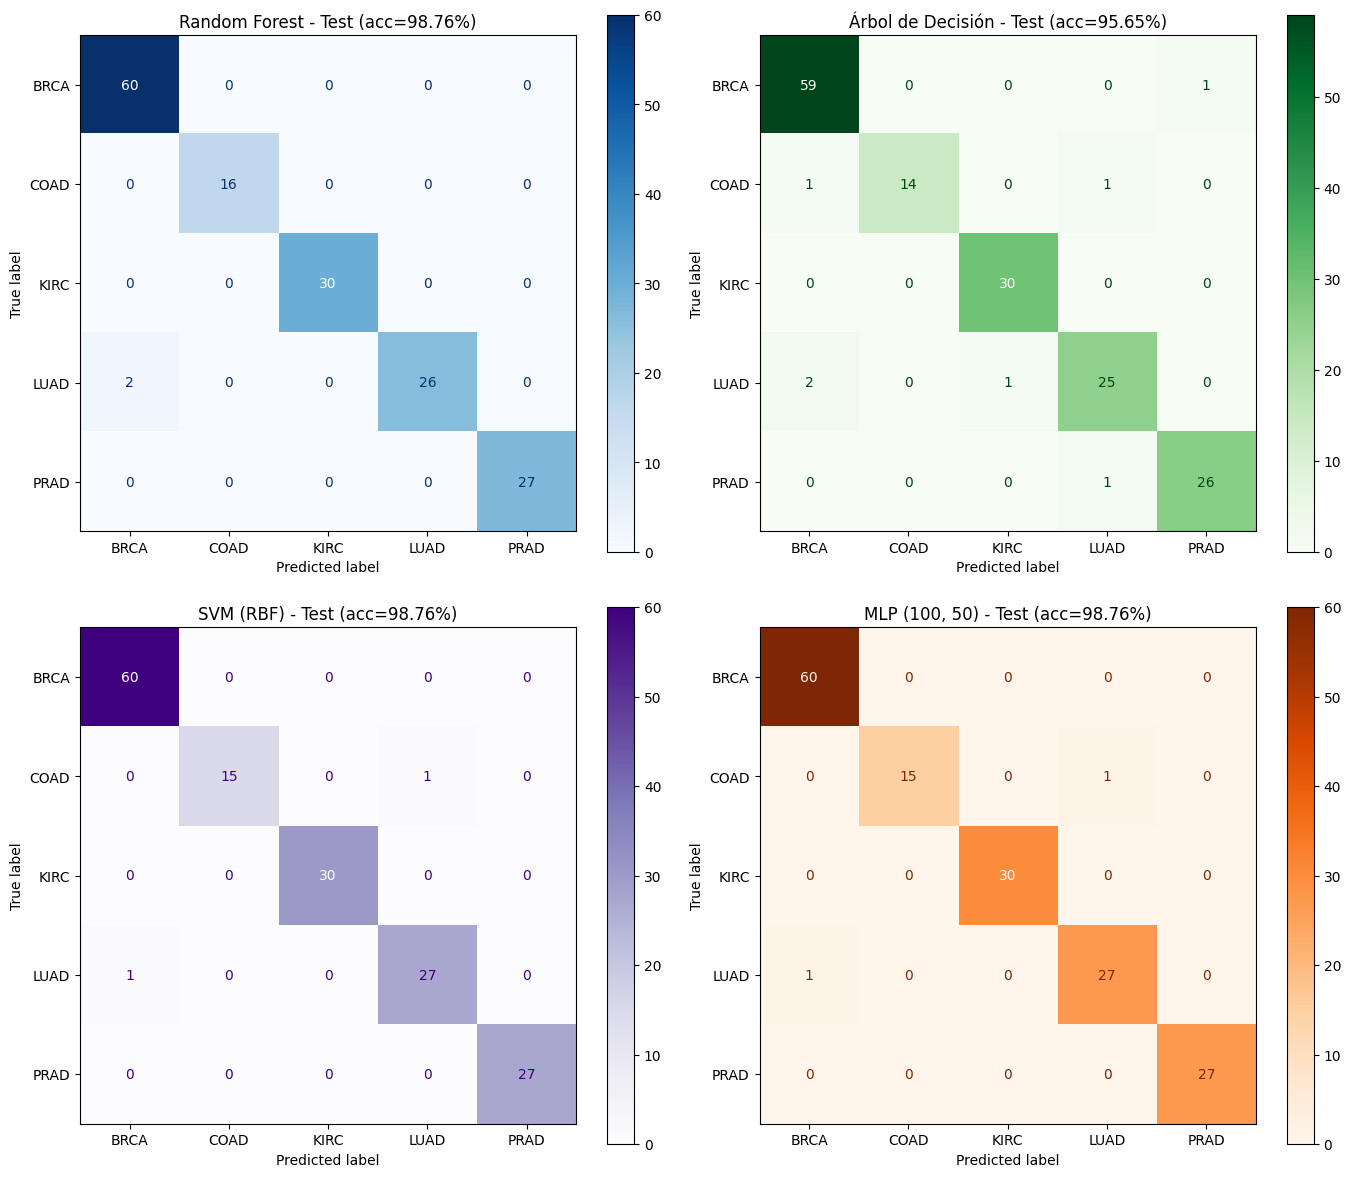

In [ ]:
# ---------------------------------------------------------
# 5. MATRICES DE CONFUSIÓN (las 4, sobre el mismo test)
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

colores = ['Blues', 'Greens', 'Purples', 'Oranges']

for i, (nombre, modelo) in enumerate(modelos.items()):
    X_te = X_test_scaled if nombre in ['SVM (RBF)', 'MLP (100, 50)'] else X_test
    y_pred = modelo.predict(X_te)
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=nombres_clases).plot(
        ax=axes[i], cmap=colores[i], values_format='d'
    )
    axes[i].set_title(f'{nombre} - Test (acc={accuracy_score(y_test, y_pred)*100:.2f}%)')

plt.tight_layout()
plt.savefig('matrices_confusion_comparativa.png', dpi=150)
plt.show()


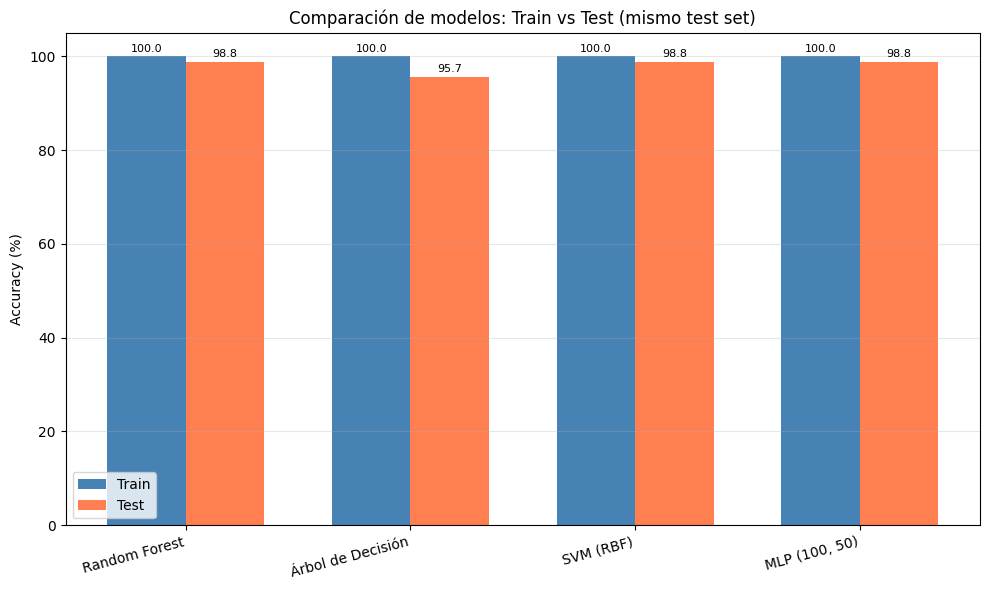

In [ ]:
# ---------------------------------------------------------
# 6. GRÁFICO DE BARRAS COMPARATIVO
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(comparativa))
ancho = 0.35

ax.bar(x - ancho/2, comparativa['Accuracy Train (%)'], ancho,
       label='Train', color='steelblue')
ax.bar(x + ancho/2, comparativa['Accuracy Test (%)'], ancho,
       label='Test', color='coral')

ax.set_xticks(x)
ax.set_xticklabels(comparativa['Modelo'], rotation=15, ha='right')
ax.set_ylabel('Accuracy (%)')
ax.set_title('Comparación de modelos: Train vs Test (mismo test set)')
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis='y', alpha=0.3)

for i, (tr, te) in enumerate(zip(comparativa['Accuracy Train (%)'],
                                  comparativa['Accuracy Test (%)'])):
    ax.text(i - ancho/2, tr + 1, f'{tr:.1f}', ha='center', fontsize=8)
    ax.text(i + ancho/2, te + 1, f'{te:.1f}', ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('comparativa_modelos.png', dpi=150)
plt.show()
